# Give Me Some Credit: EDA

By: Carlos, Alejandro and Gregorio

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/cs-training.csv")
df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [3]:
# The first column is only the row number added by Kaggle, so we drop it
df = df.drop(columns="Unnamed: 0")
df.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## 1. Data inspection
We have to understand the structure of the dataset and its variables

In [4]:
df.shape

(150000, 11)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

In [6]:
# Count the missing values of each column
df.isna().sum()

SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

The dataset has 150,000 rows and 11 columns, all numeric, so we do not need to encode categories. MonthlyIncome has 29,731 missing values (19.8%) and NumberOfDependents has 3,924 (2.6%). The rest of the columns are complete. We will decide how to fill them in the missing values section, and we will apply it after the train/test split.

In [7]:
# Rows that are exactly the same in all columns
df.duplicated().sum()

np.int64(609)

In [8]:
# Same number as a percentage of the dataset
df.duplicated().sum() / len(df) * 100

np.float64(0.406)

In [9]:
# Every copy of the duplicated rows, sorted so the identical ones are together
df[df.duplicated(keep=False)].sort_values(by=df.columns.tolist()).head(10)

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
134365,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
137102,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
25632,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
83552,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
139345,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
100594,0,0.0,21,0,0.0,NaN,1,0,0,0,0.0
127724,0,0.0,21,0,0.0,NaN,1,0,0,0,0.0
44006,0,0.0,22,0,0.0,0.0,1,0,0,0,0.0
54653,0,0.0,22,0,0.0,0.0,1,0,0,0,0.0
53012,0,0.0,22,0,0.0,1.0,2,0,0,0,0.0


In [10]:
# Keep only the extra copies (the first appearance of each row is not counted)
extra_copies = df[df.duplicated()]

len(extra_copies)

609

In [11]:
# DebtRatio equal to 0 (%): duplicates and whole dataset
print((extra_copies["DebtRatio"] == 0).mean() * 100)
print((df["DebtRatio"] == 0).mean() * 100)

98.19376026272579
2.742


In [12]:
# MonthlyIncome missing or of 1,000 or less (%): duplicates and whole dataset
print((extra_copies["MonthlyIncome"].isna() | (extra_copies["MonthlyIncome"] <= 1000)).mean() * 100)
print((df["MonthlyIncome"].isna() | (df["MonthlyIncome"] <= 1000)).mean() * 100)

98.52216748768473
23.017333333333333


In [13]:
# 2 or fewer open credit lines (%): duplicates and whole dataset
print((extra_copies["NumberOfOpenCreditLinesAndLoans"] <= 2).mean() * 100)
print((df["NumberOfOpenCreditLinesAndLoans"] <= 2).mean() * 100)

77.33990147783251
8.661333333333333


In [14]:
# Delinquency rate (%): duplicates and whole dataset
print(extra_copies["SeriousDlqin2yrs"].mean() * 100)
print(df["SeriousDlqin2yrs"].mean() * 100)

2.7914614121510675
6.683999999999999


In [15]:
# Under 30 years old (%) and median age: duplicates and whole dataset
print((extra_copies["age"] < 30).mean() * 100, extra_copies["age"].median())
print((df["age"] < 30).mean() * 100, df["age"].median())

34.646962233169134 51.0
5.8806666666666665 52.0


There are 609 duplicated rows (0.41%). The dataset has no customer ID, so we checked what kind of rows they are. Almost all of them are very simple profiles: DebtRatio is 0 in 98% of them, 98.5% have no income or an income of 1,000 or less, and 77% have two or fewer open credit lines (against 8.7% in the whole dataset). Their delinquency rate is also lower (2.79% against 6.68%). They do not look like one record copied by mistake. They look like different people with almost no credit history who happen to share the same simple values. Young borrowers are overrepresented among them: 34.6% are under 30, against 5.9% in the whole dataset, although the median age (51) is close to the overall one (52).

Decision: we keep the duplicated rows. Dropping them would remove real customers of this type, and the effect on the data is very small anyway.

When we split the data, a duplicated row can fall in train and its copy in test, so the model would be evaluated on a row it has already seen. With 609 rows (0.41%) the effect on the test metrics is negligible, so we accept it.

In [16]:
df.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


Some values look wrong. age has a minimum of 0, and the late-payment counters have a maximum of 98, far from their usual values. RevolvingUtilizationOfUnsecuredLines should be between 0 and 1, but its maximum is about 50,708. DebtRatio (maximum 329,664) and MonthlyIncome (maximum 3,008,750) also have extreme maximums, and MonthlyIncome has a minimum of 0. We only detect these problems here: the errors will be fixed in the next section and the outliers after that.

### Target distribution
The target variable is SeriousDlqin2yrs: 1 if the customer had a serious delinquency (90 days or more past due) in the next two years, 0 if not

In [17]:
# Number of customers in each class
df["SeriousDlqin2yrs"].value_counts()

SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

In [18]:
# Same, as a percentage
df["SeriousDlqin2yrs"].value_counts(normalize=True) * 100

SeriousDlqin2yrs
0    93.316
1     6.684
Name: proportion, dtype: float64

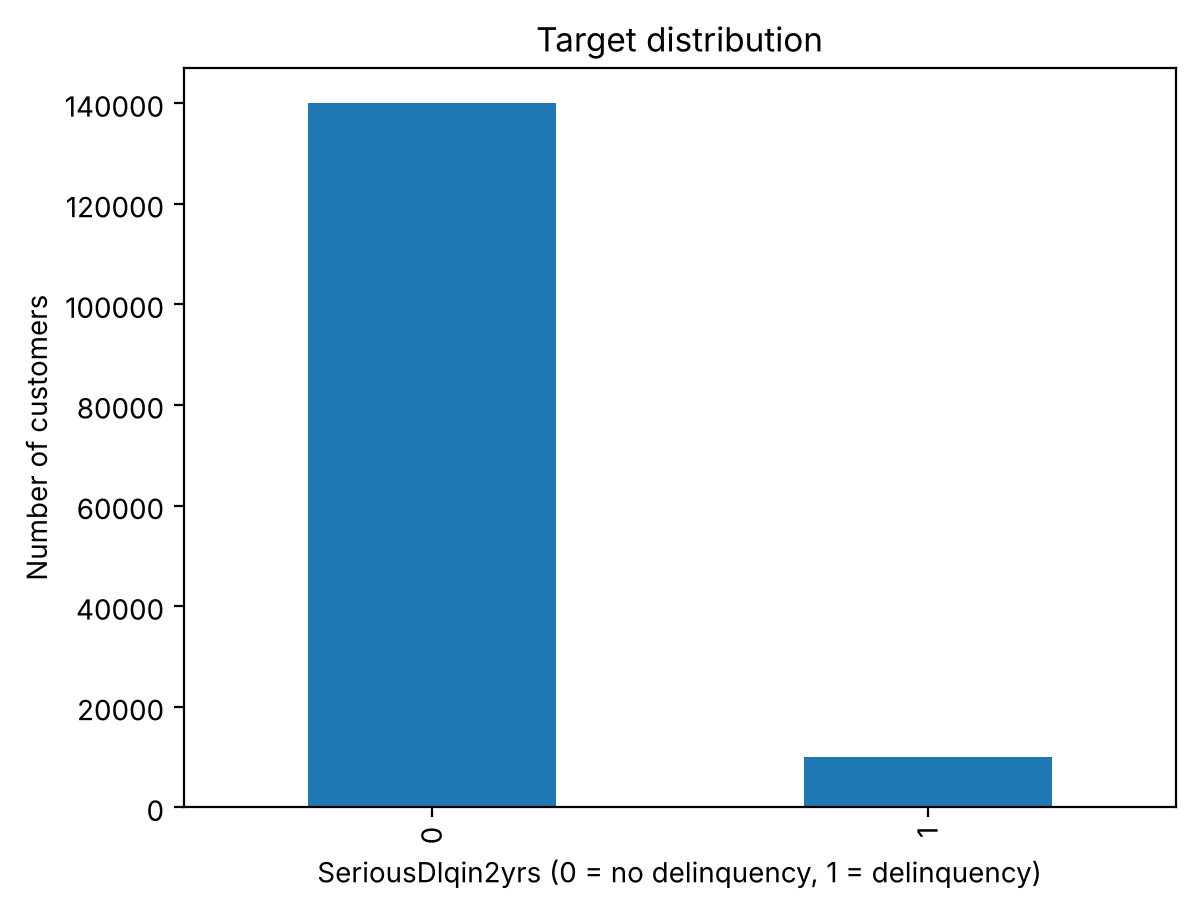

In [19]:
# Bar chart of the two classes
counts = df["SeriousDlqin2yrs"].value_counts()

counts.plot.bar()
plt.xlabel("SeriousDlqin2yrs (0 = no delinquency, 1 = delinquency)")
plt.ylabel("Number of customers")
plt.title("Target distribution")
plt.show()

In [20]:
# Accuracy of a "model" that always predicts class 0 (no delinquency)
counts[0] / len(df) * 100

np.float64(93.316)

The target is imbalanced: 10,026 customers (6.68%) had a serious delinquency and 139,974 (93.32%) did not. A model that always predicts "no delinquency" would have 93.3% accuracy and detect no one, so accuracy is not a good metric here. We will use metrics such as ROC-AUC, PR-AUC or recall, and we will split train and test with stratification so both keep the same percentage of delinquent customers.

## 2. Distribution of each variable

The `describe()` above already shows values that do not fit: an age of 0, a maximum of 98 in the three late-payment counters, a `RevolvingUtilizationOfUnsecuredLines` of 50,708 and a `DebtRatio` of 329,664. We add the skewness and the 1st and 99th percentiles. A large gap between the 99th percentile and the maximum points to extreme values or errors.

The imputation and the corrections are decided in these sections but any statistic used to fill a gap (a median, for example) will be computed on the training set only, after the split, so that no information from the test set leaks into the model.

In [21]:
# Explanatory variables (all the columns except the target)
FEATURES = df.drop(columns="SeriousDlqin2yrs").columns.tolist()

# The three late-payment counters, used several times below
LATE_COLS = ["NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTime60-89DaysPastDueNotWorse", "NumberOfTimes90DaysLate"]

In [22]:
# describe() with the 1st and 99th percentiles added
df[FEATURES].describe(percentiles=[0.01, 0.5, 0.99]).round(2)

,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.00,150000.00,150000.00,150000.00,120269.00,150000.00,150000.00,150000.00,150000.00,146076.00
mean,6.05,52.30,0.42,353.01,6670.22,8.45,0.27,1.02,0.24,0.76
std,249.76,14.77,4.19,2037.82,14384.67,5.15,4.17,1.13,4.16,1.12
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1%,0.00,24.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,0.15,52.00,0.00,0.37,5400.00,8.00,0.00,1.00,0.00,0.00
99%,1.09,87.00,4.00,4979.04,25000.00,24.00,3.00,4.00,2.00,4.00
max,50708.00,109.00,98.00,329664.00,3008750.00,58.00,98.00,54.00,98.00,20.00


In [23]:
# Skewness: 0 means symmetric, large positive values mean a long right tail
df[FEATURES].skew().round(2)

RevolvingUtilizationOfUnsecuredLines     97.63
age                                       0.19
NumberOfTime30-59DaysPastDueNotWorse     22.60
DebtRatio                                95.16
MonthlyIncome                           114.04
NumberOfOpenCreditLinesAndLoans           1.22
NumberOfTimes90DaysLate                  23.09
NumberRealEstateLoansOrLines              3.48
NumberOfTime60-89DaysPastDueNotWorse     23.33
NumberOfDependents                        1.59
dtype: float64

The histograms below are cut at the 99th percentile of each variable. Without the cut, a handful of extreme values stretches the axis and the bulk of the data collapses into a single bar.

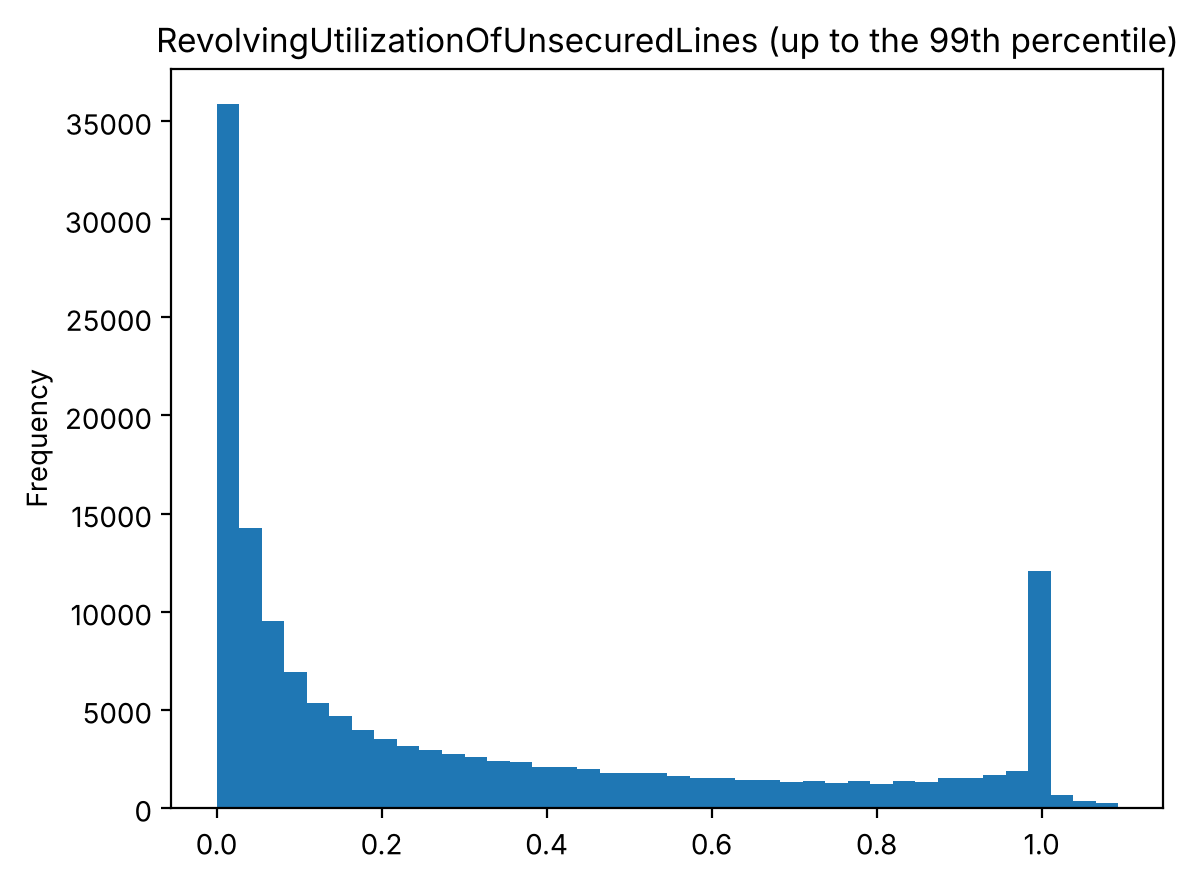

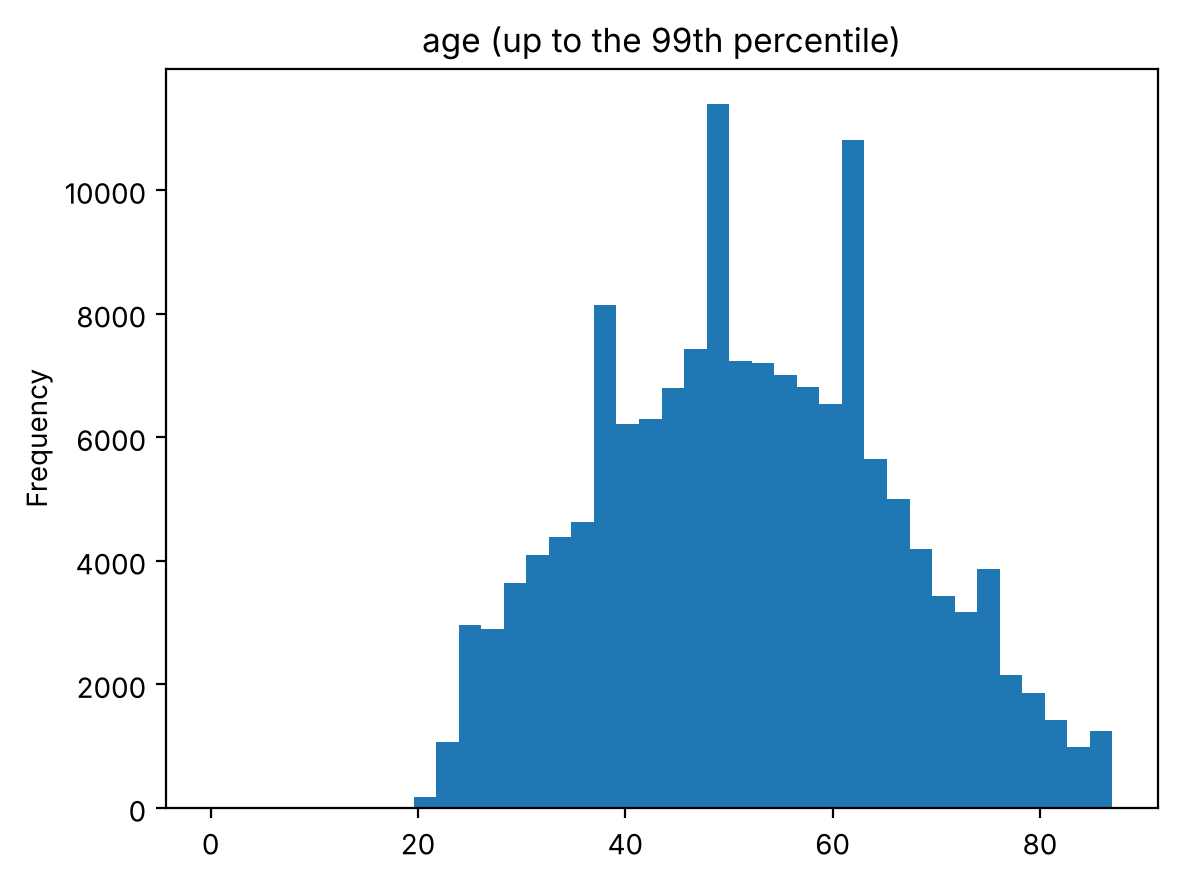

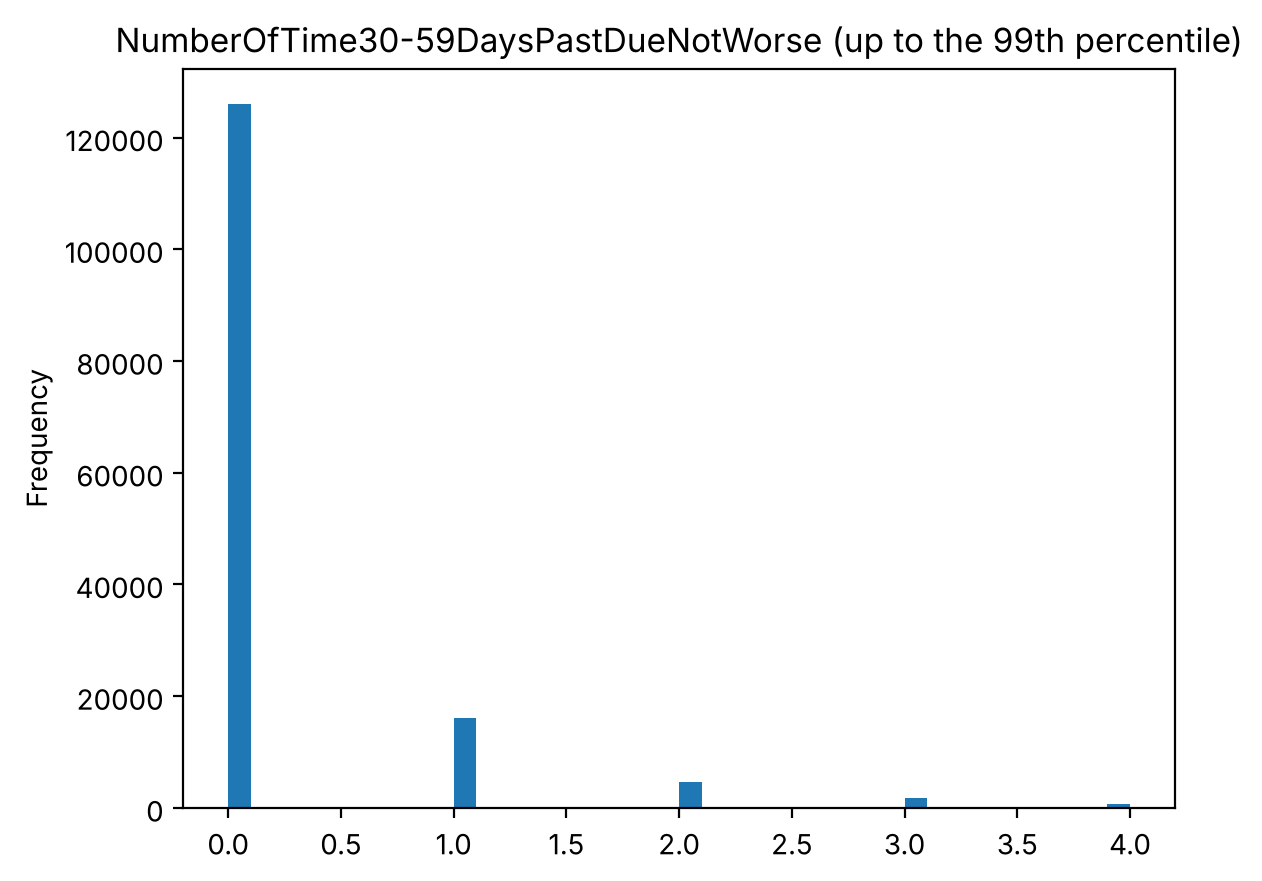

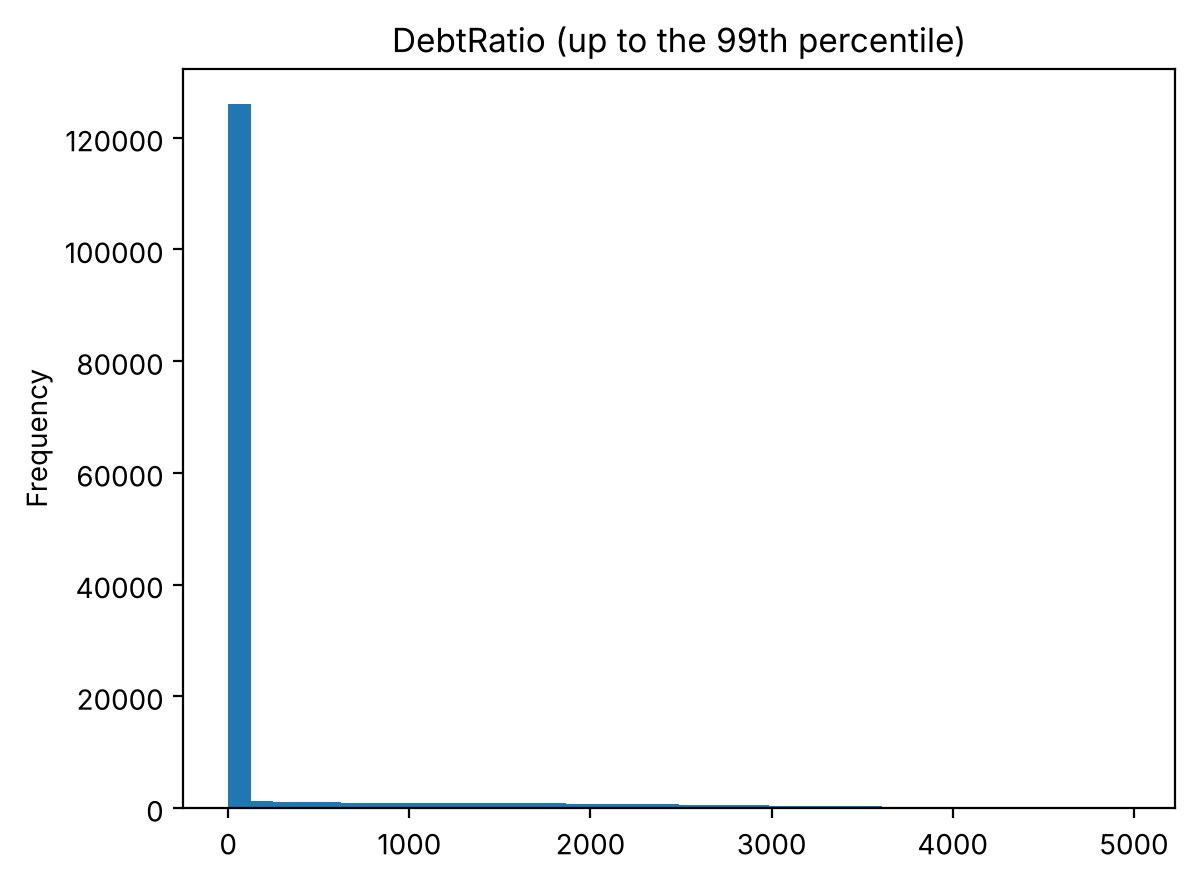

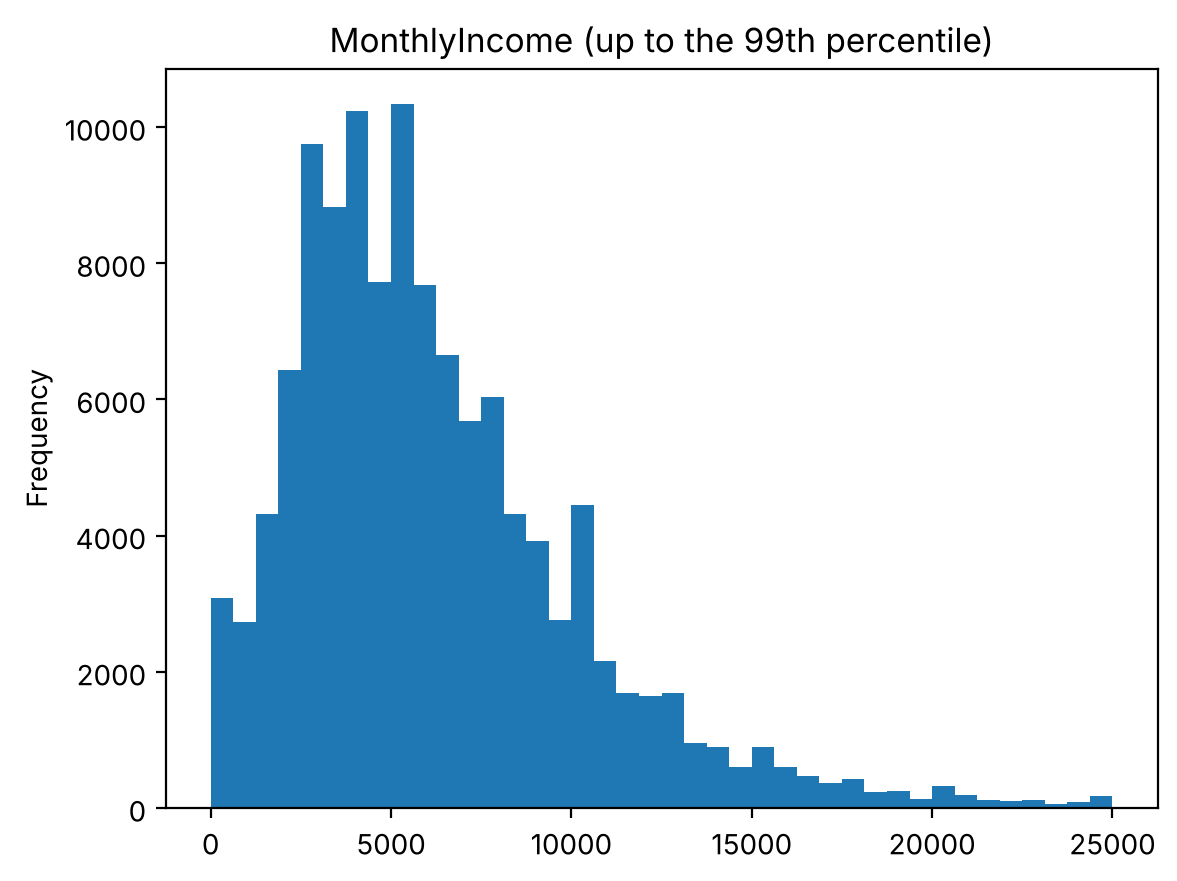

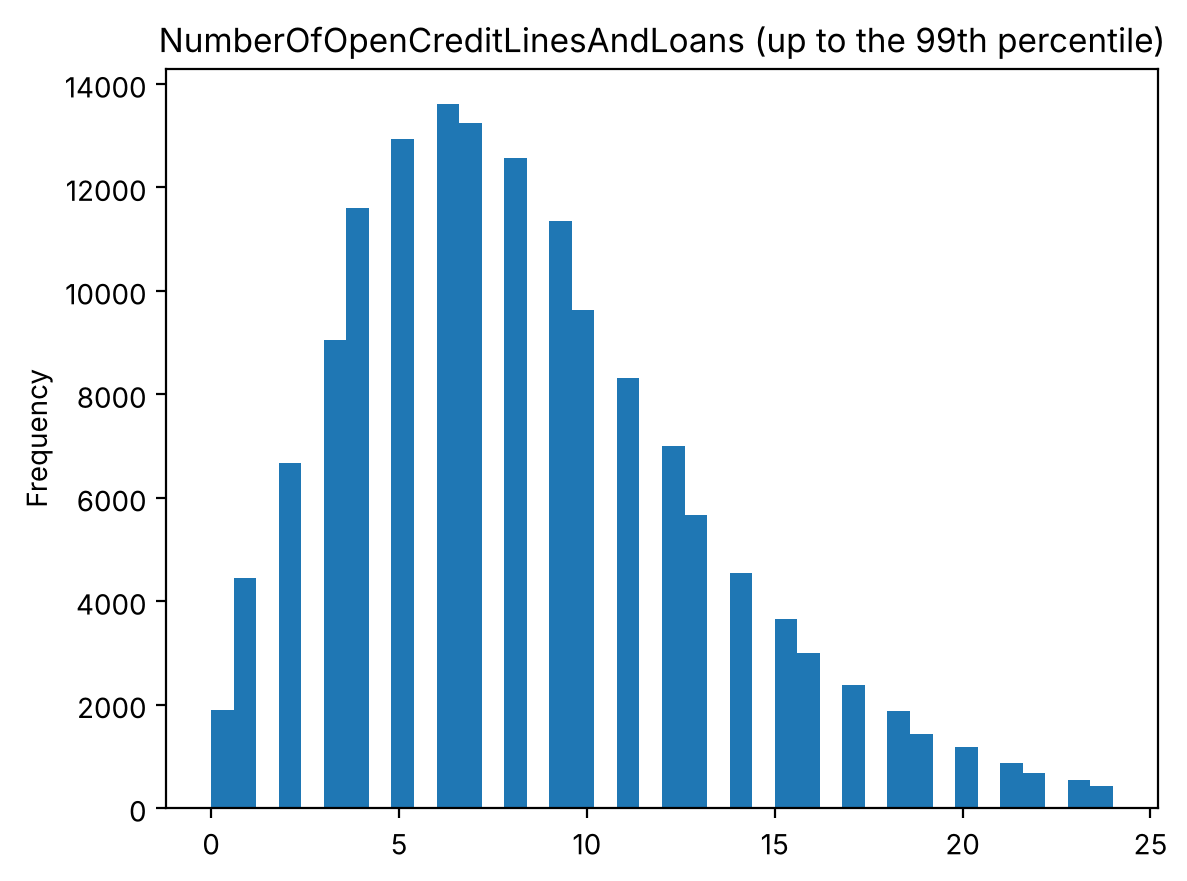

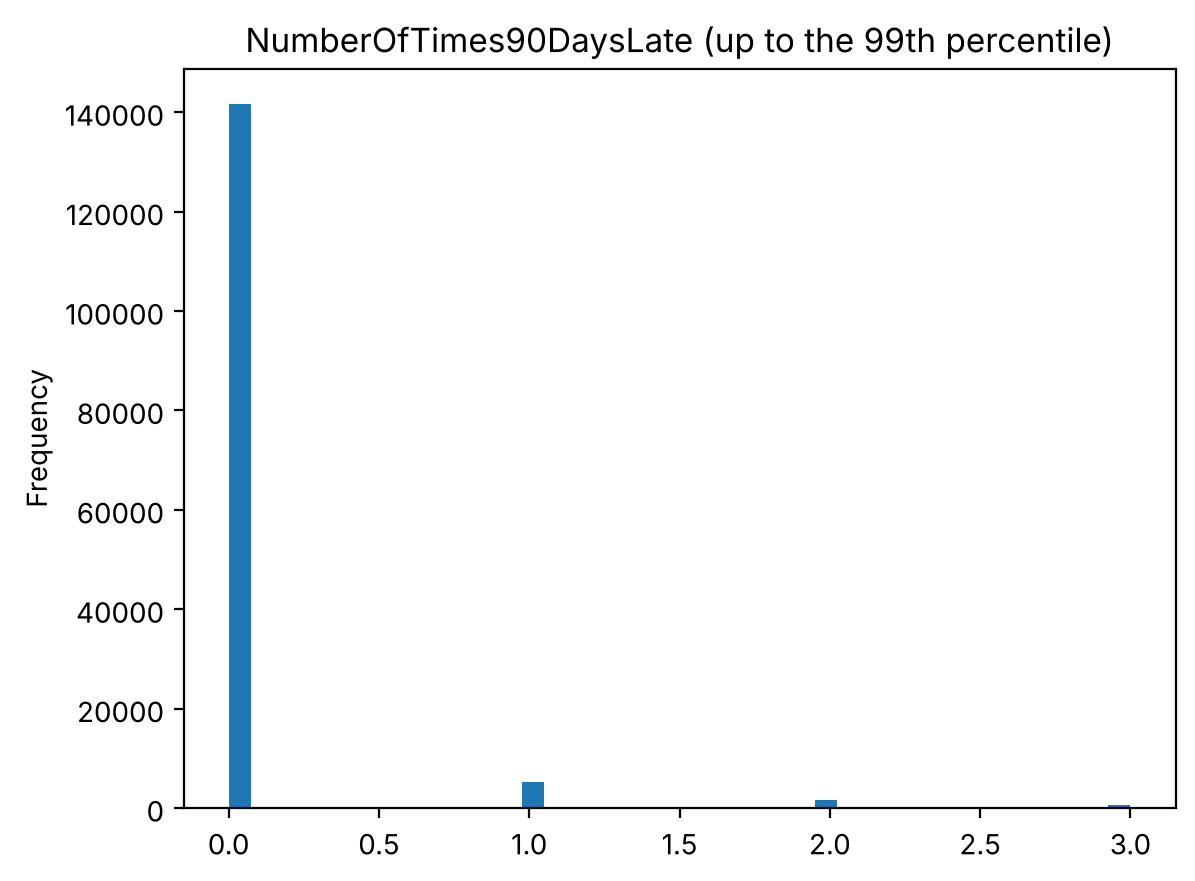

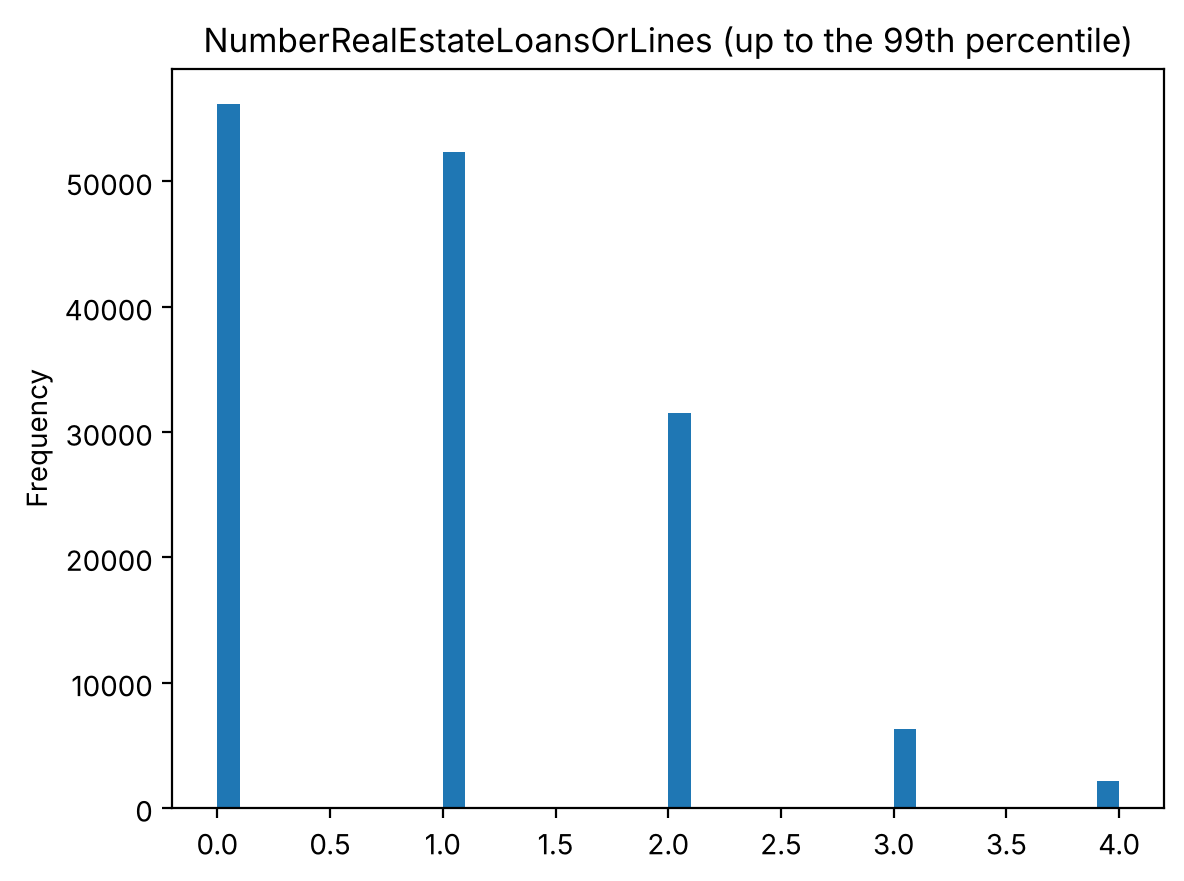

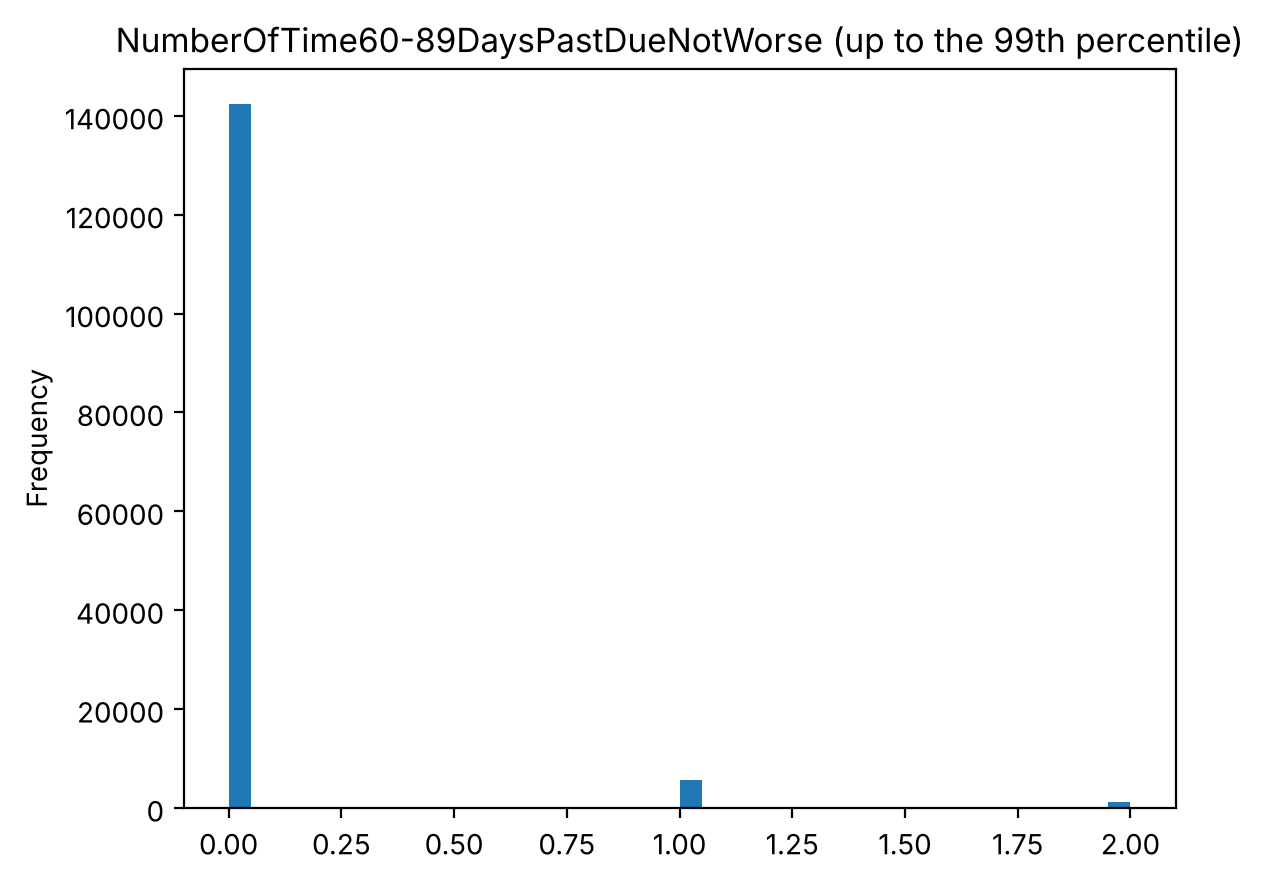

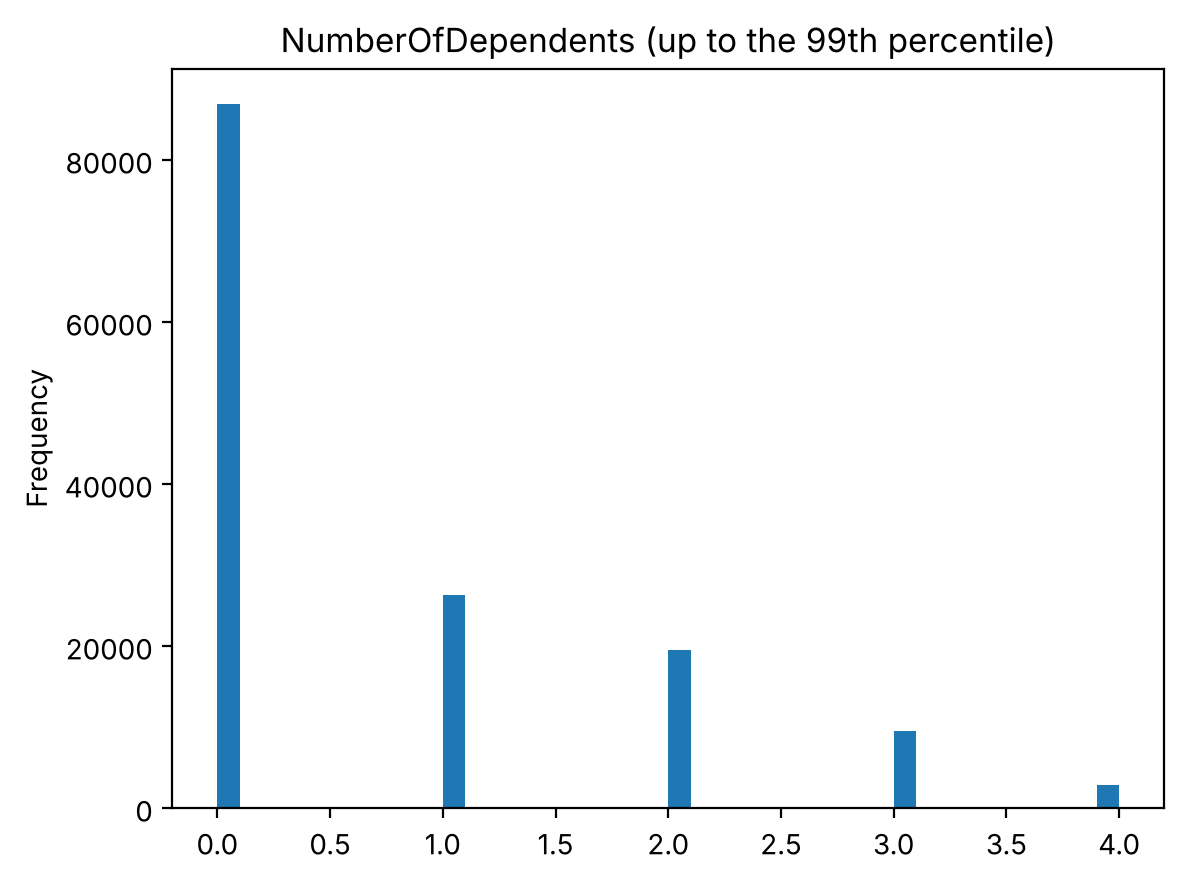

In [24]:
# One histogram per variable, cut at its 99th percentile
for col in FEATURES:
    upper = df[col].quantile(0.99)
    df[df[col] <= upper][col].plot.hist(bins=40)
    plt.title(col + " (up to the 99th percentile)")
    plt.show()

### Conclusions on distributions

- `RevolvingUtilizationOfUnsecuredLines`: the median is 0.15 and the 99th percentile 1.09, but the maximum is 50,708. The plot shows two spikes, one at 0 (no balance) and one at exactly 1 (card at its limit). Values slightly above 1 are possible, values in the thousands are not.
- `DebtRatio`: the median is 0.37 and the 99th percentile 4,979, with a maximum of 329,664. The shape of the plot does not come from a ratio with a long tail. It comes from a group of rows where the column holds large numbers, which we explain in section 4.3.
- `MonthlyIncome`: right-skewed (skewness 114), median 5,400, 99th percentile 25,000 and maximum 3,008,750. About 1,600 borrowers declare an income of exactly 0.
- The three late-payment counters have a skewness of 22 to 23 and a maximum of 98. The 98 is not a count. After removing the codes 96 and 98 (section 4.2) the skewness drops to between 4 and 9 and the maximum to between 11 and 17.
- `NumberOfOpenCreditLinesAndLoans`, `NumberRealEstateLoansOrLines` and `NumberOfDependents` are counts with a mode at a low value and a right tail. `age` is the only variable close to symmetric, with a minimum of 0 and a maximum of 109 that we check in section 4.1.

Action: no transformation here. The summary statistics are distorted by errors (codes 96 and 98, ratios that are amounts), so we first correct the errors in section 4. Extreme values that remain after that are treated in the outlier section, and the logarithm is considered after capping, because the log of an uncapped variable keeps a very long tail.

## 3. Missing values

The `isna().sum()` above shows missing values in two columns only: `MonthlyIncome` and `NumberOfDependents`. We put them as a percentage and then check whether the missingness says something about the target.

In [25]:
# Percentage of missing values in each column
(df.isna().sum() / len(df) * 100).round(2)

SeriousDlqin2yrs                         0.00
RevolvingUtilizationOfUnsecuredLines     0.00
age                                      0.00
NumberOfTime30-59DaysPastDueNotWorse     0.00
DebtRatio                                0.00
MonthlyIncome                           19.82
NumberOfOpenCreditLinesAndLoans          0.00
NumberOfTimes90DaysLate                  0.00
NumberRealEstateLoansOrLines             0.00
NumberOfTime60-89DaysPastDueNotWorse     0.00
NumberOfDependents                       2.62
dtype: float64

First question: is a missing value just random noise, or does it relate to the target? We compare the default rate of borrowers with and without the value.

In [26]:
# Default rate when MonthlyIncome is missing and when it is observed
print("Income missing: ", df[df["MonthlyIncome"].isna()]["SeriousDlqin2yrs"].mean())
print("Income observed:", df[df["MonthlyIncome"].notna()]["SeriousDlqin2yrs"].mean())

Income missing:  0.05613669234132723
Income observed: 0.06948590243537403


In [27]:
# Same check for NumberOfDependents
print("Dependents missing: ", df[df["NumberOfDependents"].isna()]["SeriousDlqin2yrs"].mean())
print("Dependents observed:", df[df["NumberOfDependents"].notna()]["SeriousDlqin2yrs"].mean())

Dependents missing:  0.04561671763506626
Dependents observed: 0.0674101152824557


Second question: do the two variables go missing together?

In [28]:
# Rows: income missing (True) or not. Columns: dependents missing (True) or not
pd.crosstab(df["MonthlyIncome"].isna(), df["NumberOfDependents"].isna())

NumberOfDependents,False,True
MonthlyIncome,,
False,120269,0
True,25807,3924


In [29]:
# Inside the missing-income group: default rate with and without dependents
no_income = df[df["MonthlyIncome"].isna()]

print("Dependents missing: ", no_income[no_income["NumberOfDependents"].isna()]["SeriousDlqin2yrs"].mean())
print("Dependents observed:", no_income[no_income["NumberOfDependents"].notna()]["SeriousDlqin2yrs"].mean())

Dependents missing:  0.04561671763506626
Dependents observed: 0.05773627310419654


Third question: do borrowers with missing income look different from the rest in the other variables?

In [30]:
# Median of some variables. False = income observed, True = income missing
df.groupby(df["MonthlyIncome"].isna())[["age", "DebtRatio", "RevolvingUtilizationOfUnsecuredLines", "NumberOfOpenCreditLinesAndLoans"]].median()

,age,DebtRatio,RevolvingUtilizationOfUnsecuredLines,NumberOfOpenCreditLinesAndLoans
MonthlyIncome,,,,
False,51.0,0.296023,0.177282,8.0
True,57.0,1159.000000,0.081697,6.0


### Conclusions and decision on missing values

What the data shows:

- `MonthlyIncome` is missing in 29,731 rows (19.82%) and `NumberOfDependents` in 3,924 rows (2.62%).
- The missingness is related to the target. The default rate is 5.6% when the income is missing and 7.0% when it is observed. The groups also differ in other variables: the median age is 57 against 51, the median utilization 0.08 against 0.18, and the median number of open credit lines 6 against 8. The values are not missing at random.
- All 3,924 missing dependents fall inside the 29,731 rows with missing income. Both variables are missing together, which suggests the same origin (probably borrowers whose profile was never filled in). Within that group, the default rate is 4.6% when the dependents are missing and 5.8% when they are observed, a small difference.

Decisions:

- `MonthlyIncome`: impute with the median of the training set and add the indicator `income_missing`. The median is used because income is strongly right-skewed and the mean would be pulled up by the extreme values. The indicator keeps the information that the value was absent, which we have just seen is related to the target. Dropping the rows would remove a fifth of the file and change the population we model.
- `NumberOfDependents`: impute with the median of the training set, which is 0 and also the mode. Since the missing dependents are a subset of the missing incomes, `income_missing` already carries that information and no second indicator is added.
- Model-based imputation (KNN or iterative) is left as an option for the modelling stage. It costs more and the gain is uncertain when the missingness is concentrated in one group of borrowers.

When we reach the modelling stage the imputer is fitted on `X_train` only:

```python
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
X_train_imp = imputer.fit_transform(X_train)   # medians computed on train
X_test_imp = imputer.transform(X_test)         # same medians applied to test
```

## 4. Erroneous data

### 4.1 Age

In [31]:
# Borrowers under 18 and over 100
print("Under 18:", (df["age"] < 18).sum())
print("Over 100:", (df["age"] > 100).sum())

Under 18: 1
Over 100: 13


In [32]:
df["age"].describe().round(1)

count    150000.0
mean         52.3
std          14.8
min           0.0
25%          41.0
50%          52.0
75%          63.0
max         109.0
Name: age, dtype: float64

Conclusion: there is one borrower of age 0, which is impossible. We treat any age below 18 as an error, because a minor cannot sign a loan contract. The 13 borrowers over 100 (maximum 109) are unusual but possible, so we keep them and leave them to the outlier section.

Action: set ages below 18 to missing and impute with the training median after the split. With a single row, the effect on the model is negligible, but the value would distort the minimum of the variable.

### 4.2 Codes 96 and 98 in the late-payment counters

The three late-payment variables count events in a two-year window. We look at their largest values.

In [33]:
df["NumberOfTime30-59DaysPastDueNotWorse"].value_counts().sort_index().tail(6)

NumberOfTime30-59DaysPastDueNotWorse
10      4
11      1
12      2
13      1
96      5
98    264
Name: count, dtype: int64

In [34]:
df["NumberOfTime60-89DaysPastDueNotWorse"].value_counts().sort_index().tail(6)

NumberOfTime60-89DaysPastDueNotWorse
7       9
8       2
9       1
11      1
96      5
98    264
Name: count, dtype: int64

In [35]:
df["NumberOfTimes90DaysLate"].value_counts().sort_index().tail(6)

NumberOfTimes90DaysLate
13      4
14      2
15      2
17      1
96      5
98    264
Name: count, dtype: int64

In [36]:
# Number of 96 or 98 codes in each counter
df[LATE_COLS].isin([96, 98]).sum()

NumberOfTime30-59DaysPastDueNotWorse    269
NumberOfTime60-89DaysPastDueNotWorse    269
NumberOfTimes90DaysLate                 269
dtype: int64

In [37]:
# Rows with a code in the 30-59 days counter: do the other two counters carry it too?
special = df["NumberOfTime30-59DaysPastDueNotWorse"].isin([96, 98])

df[special][LATE_COLS].value_counts()

NumberOfTime30-59DaysPastDueNotWorse  NumberOfTime60-89DaysPastDueNotWorse  NumberOfTimes90DaysLate
98                                    98                                    98                         264
96                                    96                                    96                           5
Name: count, dtype: int64

In [38]:
# Largest value of each counter in the rows without the code
df[~special][LATE_COLS].max()

NumberOfTime30-59DaysPastDueNotWorse    13
NumberOfTime60-89DaysPastDueNotWorse    11
NumberOfTimes90DaysLate                 17
dtype: int64

In [39]:
# Default rate of the rows with the code and of the rest
print("With 96/98:", df[special]["SeriousDlqin2yrs"].mean())
print("Rest:      ", df[~special]["SeriousDlqin2yrs"].mean())

With 96/98: 0.5464684014869888
Rest:       0.06597832112254644


Conclusions:

- 269 rows carry a 96 (5 rows) or a 98 (264 rows), and they carry it in the three counters at the same time. Nobody has 98 late payments of 30 to 59 days in a two-year window. Once the codes are excluded, the largest values are 13, 11 and 17. The two values are codes of the data source, not counts.
- Those rows have a default rate of 54.7%, against 6.6% in the rest of the file. The code is not noise. It marks a group of borrowers that is very different from the others.

Action: replace 96 and 98 by missing values in the three counters and add a flag `late_code_flag` that marks the 269 rows, so that the information is not lost. The missing values are imputed later with the training median. If we kept the 98 as a number, it would dominate any model that uses the counters, and if we only deleted it we would throw away the strongest signal of these rows.

### 4.3 DebtRatio when income is missing

By definition `DebtRatio` is monthly debt payments divided by monthly income, so it should be a small number for most people. We check its behaviour in the two income groups.

In [40]:
# DebtRatio when the income is observed
df[df["MonthlyIncome"].notna()]["DebtRatio"].describe(percentiles=[0.5, 0.9, 0.99]).round(2)

count    120269.00
mean         26.60
std         424.45
min           0.00
50%           0.30
90%           0.76
99%         661.82
max       61106.50
Name: DebtRatio, dtype: float64

In [41]:
# DebtRatio when the income is missing
df[df["MonthlyIncome"].isna()]["DebtRatio"].describe(percentiles=[0.5, 0.9, 0.99]).round(2)

count     29731.00
mean       1673.40
std        4248.37
min           0.00
50%        1159.00
90%        3785.00
99%        8084.50
max      329664.00
Name: DebtRatio, dtype: float64

In [42]:
# Share of rows with DebtRatio above 1 (%) in each group
print("Income observed:", (df[df["MonthlyIncome"].notna()]["DebtRatio"] > 1).mean() * 100)
print("Income missing: ", (df[df["MonthlyIncome"].isna()]["DebtRatio"] > 1).mean() * 100)

Income observed: 6.014018575027647
Income missing:  93.85489892704585


In [43]:
# Borrowers that declare an income of exactly 0, and their DebtRatio
print("MonthlyIncome == 0:", (df["MonthlyIncome"] == 0).sum())

df[df["MonthlyIncome"] == 0]["DebtRatio"].describe(percentiles=[0.5, 0.9]).round(1)

MonthlyIncome == 0: 1634


count     1634.0
mean      1573.6
std       2818.0
min          0.0
50%        930.0
90%       3587.9
max      60212.0
Name: DebtRatio, dtype: float64

In [44]:
# DebtRatio of the borrowers with a positive income
df[df["MonthlyIncome"] > 0]["DebtRatio"].describe(percentiles=[0.5, 0.99]).round(2)

count    118635.00
mean          5.29
std         199.77
min           0.00
50%           0.29
99%           2.99
max       61106.50
Name: DebtRatio, dtype: float64

Conclusions:

- When the income is observed, the median `DebtRatio` is 0.30 and only 6% of the rows are above 1. When the income is missing, the median is 1,159 and 93.9% of the rows are above 1.
- The 1,634 borrowers with an income of exactly 0 behave like the missing-income group, with a median `DebtRatio` of 930. A ratio needs an income to divide by. When the income is missing or 0, the column holds an absolute amount of debt, which is not comparable with a ratio.
- That explains the `DebtRatio` histogram in section 2: one spike near 0 and a long flat tail up to 5,000. They are two different populations in the same column.

Action: set `DebtRatio` to missing wherever `MonthlyIncome` is missing or equal to 0, and impute it later with the training median. We keep `MonthlyIncome == 0` itself as it is, because a borrower can declare no income, and `income_missing` already marks the missing ones. The extreme `DebtRatio` values among borrowers with a positive income (99th percentile 2.99, maximum 61,106) remain as an outlier problem for the outlier section.

### 4.4 Applying the corrections

The cell below applies the three corrections on a copy of the data, `df_fixed`, so that `df` keeps the original values for comparison. The corrections use no statistic computed from the data (they only check fixed rules), so they can be applied to the whole file before the split without leaking information. The imputation of the new missing values stays for after the split.

In [45]:
df_fixed = df.copy()

# The flags go first: once the values are replaced we could not tell
# which rows had a code or a missing income.
# special marks the rows with 96/98 (the three counters share them, see 4.2)
df_fixed["late_code_flag"] = special.astype(int)
df_fixed["income_missing"] = df_fixed["MonthlyIncome"].isna().astype(int)

# Impossible age: a minor cannot hold a credit
df_fixed.loc[df_fixed["age"] < 18, "age"] = np.nan

# 96 and 98 are codes of the data source, not real counts
for col in LATE_COLS:
    df_fixed.loc[df_fixed[col].isin([96, 98]), col] = np.nan

# Without an income (missing or 0) DebtRatio is an amount, not a ratio
no_income_rows = df_fixed["MonthlyIncome"].isna() | (df_fixed["MonthlyIncome"] == 0)
df_fixed.loc[no_income_rows, "DebtRatio"] = np.nan

# Missing values after the corrections
df_fixed.isna().sum()

SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         1
NumberOfTime30-59DaysPastDueNotWorse      269
DebtRatio                               31365
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                   269
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse      269
NumberOfDependents                       3924
late_code_flag                              0
income_missing                              0
dtype: int64

In [46]:
# Skewness of the corrected variables, before and after
print(df[LATE_COLS + ["DebtRatio"]].skew().round(1))
print(df_fixed[LATE_COLS + ["DebtRatio"]].skew().round(1))

NumberOfTime30-59DaysPastDueNotWorse    22.6
NumberOfTime60-89DaysPastDueNotWorse    23.3
NumberOfTimes90DaysLate                 23.1
DebtRatio                               95.2
dtype: float64
NumberOfTime30-59DaysPastDueNotWorse      4.2
NumberOfTime60-89DaysPastDueNotWorse      7.5
NumberOfTimes90DaysLate                   9.3
DebtRatio                               244.4
dtype: float64


The corrections lower the skewness of the three counters (from 23 to between 4 and 9) and leave 31,365 missing values in `DebtRatio` (29,731 without income and 1,634 with income 0). The skewness of `DebtRatio` goes up, from 95 to 244. After removing the amounts, the body of the variable has a median of 0.30, so the extreme values that remain (up to 61,106) weigh more. They do not come from the income problem and need their own treatment in the outlier section.

## 5. Outliers

We work on `df_fixed`, so the thresholds are not computed over values that section 4 already identified as errors.

We start with the IQR rule: a value is flagged when it lies more than 1.5 times the interquartile range above the third quartile. We use it instead of the distance in standard deviations seen in class because these variables are very skewed. In a skewed variable the extreme values inflate the standard deviation that is supposed to detect them.

In [47]:
# Upper IQR fence of each variable: Q3 + 1.5 * (Q3 - Q1)
q1 = df_fixed[FEATURES].quantile(0.25)
q3 = df_fixed[FEATURES].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)

# Number of rows above the fence in each variable (True counts as 1 when we sum)
rows_above = (df_fixed[FEATURES] > upper).sum()

pd.DataFrame({"fence": upper.round(2), "rows above": rows_above})

,fence,rows above
RevolvingUtilizationOfUnsecuredLines,1.35,763
age,96.00,45
NumberOfTime30-59DaysPastDueNotWorse,0.00,23713
DebtRatio,0.97,6070
MonthlyIncome,15522.50,4879
NumberOfOpenCreditLinesAndLoans,20.00,3980
NumberOfTimes90DaysLate,0.00,8069
NumberRealEstateLoansOrLines,5.00,793
NumberOfTime60-89DaysPastDueNotWorse,0.00,7335
NumberOfDependents,2.50,13336


The IQR rule alone cannot decide anything here:

- In the three late-payment counters the first and third quartiles are 0, so the fence is 0 and every borrower with at least one late payment is flagged (23,713 rows in the 30-59 days counter). Section 6 shows that these rows have the highest default rates of the dataset. Treating them as outliers would remove the main signal of the problem.
- In `NumberOfDependents` the fence is 2.5, so the rule flags 13,336 borrowers with three or more dependents. That is a normal family size.
- In `RevolvingUtilizationOfUnsecuredLines`, `DebtRatio` and `MonthlyIncome` the rule flags 763, 6,070 and 4,879 rows. They mix plausible values with impossible ones.

So we study each variable separately: where the extreme values are and how the default rate behaves in them. In each case we decide whether the value is an error, a real but extreme value, or a value that carries information.

### 5.1 RevolvingUtilizationOfUnsecuredLines

The variable is the balance of the credit cards and personal lines divided by their limit. A value of 1 means the lines are at their limit. A value somewhat above 1 is possible, because interest and fees can take the balance over the limit. A value of 1,571, the 99.9th percentile, is not.

In [48]:
df_fixed["RevolvingUtilizationOfUnsecuredLines"].describe(percentiles=[0.5, 0.99, 0.999]).round(2)

count    150000.00
mean          6.05
std         249.76
min           0.00
50%           0.15
99%           1.09
99.9%      1571.01
max       50708.00
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64

In [49]:
# Default rate by range of utilization
bins = [0, 0.5, 1, 2, 10, 100, 60000]
ranges = pd.cut(df_fixed["RevolvingUtilizationOfUnsecuredLines"], bins=bins, include_lowest=True)

df_fixed.groupby(ranges, observed=True)["SeriousDlqin2yrs"].agg(["count", "mean"]).round(3)

,count,mean
RevolvingUtilizationOfUnsecuredLines,,
"(-0.001, 0.5]",108712,0.027
"(0.5, 1.0]",37967,0.153
"(1.0, 2.0]",2950,0.401
"(2.0, 10.0]",130,0.285
"(10.0, 100.0]",18,0.333
"(100.0, 60000.0]",223,0.049


Conclusions:

- The default rate rises with utilization: 2.7% up to 0.5, 15.3% between 0.5 and 1, and 40.1% between 1 and 2. Borrowers above their limit are the riskiest group. The 130 rows between 2 and 10 still behave like them, with a default rate of 28.5%.
- Above 10 the pattern breaks. The 223 rows above 100 have a default rate of 4.9%, below the average of the dataset. These values cannot be ratios. They are probably balances recorded in the wrong field. The 18 rows between 10 and 100 are too few to show a pattern.

Action: set utilization above 10 to missing (241 rows, 0.16%) and impute it after the split with the training median. The threshold 10 is a fixed rule, so it can be applied now without leakage. Capping these rows at a high value instead would place borrowers with a 4.9% default rate in the riskiest range of the variable. Values between 1 and 10 are kept as they are, because they carry the strongest signal of the variable.

### 5.2 DebtRatio with a positive income

After section 4, `DebtRatio` only has values for borrowers with a positive income. The median is 0.29 and the 99th percentile 2.99, but the 99.9th percentile is 1,467 and the maximum 61,106. We look at who has a ratio above 100.

In [50]:
# DebtRatio after section 4 (only rows with a positive income)
df_fixed["DebtRatio"].describe(percentiles=[0.5, 0.99, 0.999]).round(2)

count    118635.00
mean          5.29
std         199.77
min           0.00
50%           0.29
99%           2.99
99.9%      1467.15
max       61106.50
Name: DebtRatio, dtype: float64

In [51]:
# Income of the rows with DebtRatio above 100
df_fixed[df_fixed["DebtRatio"] > 100]["MonthlyIncome"].describe().round(1)

count    468.0
mean       2.1
std       18.6
min        1.0
25%        1.0
50%        1.0
75%        1.0
max      401.0
Name: MonthlyIncome, dtype: float64

In [52]:
# How many borrowers declare a monthly income between 1 and 99
tiny_income = (df_fixed["MonthlyIncome"] > 0) & (df_fixed["MonthlyIncome"] < 100)

print("Income between 1 and 99:", tiny_income.sum())
print("Income exactly 1:      ", (df_fixed["MonthlyIncome"] == 1).sum())
print("Default rate:          ", df_fixed[tiny_income]["SeriousDlqin2yrs"].mean())

Income between 1 and 99: 643
Income exactly 1:       605
Default rate:           0.027993779160186624


In [53]:
# DebtRatio once those rows are excluded
df_fixed[df_fixed["MonthlyIncome"] >= 100]["DebtRatio"].describe(percentiles=[0.5, 0.99, 0.999]).round(2)

count    117992.00
mean          0.39
std           1.02
min           0.00
50%           0.29
99%           2.02
99.9%         8.70
max         170.40
Name: DebtRatio, dtype: float64

In [54]:
# Default rate by range of DebtRatio (income of 100 or more)
real_ratio = df_fixed[df_fixed["MonthlyIncome"] >= 100]
ranges = pd.cut(real_ratio["DebtRatio"], bins=[0, 0.5, 1, 2, 5, 20, 1000], include_lowest=True)

real_ratio.groupby(ranges, observed=True)["SeriousDlqin2yrs"].agg(["count", "mean"]).round(3)

,count,mean
DebtRatio,,
"(-0.001, 0.5]",91938,0.060
"(0.5, 1.0]",20933,0.099
"(1.0, 2.0]",3920,0.137
"(2.0, 5.0]",911,0.105
"(5.0, 20.0]",259,0.077
"(20.0, 1000.0]",31,0.161


Conclusions:

- The 468 rows with `DebtRatio` above 100 have a median income of 1. This is the problem of 4.3 again: dividing by an income of 1 leaves the debt amount unchanged, so the column holds an amount.
- 643 borrowers declare a monthly income between 1 and 99, 605 of them exactly 1. Their default rate is 2.8%, less than half the average. A monthly income of 1 is a placeholder of the data source.
- Once those rows are excluded, the variable is a ratio again: median 0.29, 99th percentile 2.02, 99.9th percentile 8.70 and maximum 170.
- The default rate rises from 6.0% (ratio up to 0.5) to 13.7% (ratio between 1 and 2) and does not keep rising for larger ratios. Those ranges have few rows: 911 between 2 and 5, 259 between 5 and 20 and 31 above 20.

Actions:

- Set `DebtRatio` to missing when the income is below 100 (643 rows) and impute it after the split. This extends the rule of 4.3. The threshold 100 is fixed by hand: a monthly income below that cannot pay any debt.
- Cap the remaining values at the 99th percentile of the training set (about 2) after the split. The cap stops a few ratios between 20 and 170 from dominating linear models. After the cap the variable stays between 0 and about 2, so a logarithm adds little.

### 5.3 MonthlyIncome

In [55]:
df_fixed["MonthlyIncome"].describe(percentiles=[0.01, 0.5, 0.99, 0.999]).round(0)

count     120269.0
mean        6670.0
std        14385.0
min            0.0
1%             0.0
50%         5400.0
99%        25000.0
99.9%      78396.0
max      3008750.0
Name: MonthlyIncome, dtype: float64

In [56]:
# Default rate by income quintile
quintiles = pd.qcut(df_fixed["MonthlyIncome"], q=5)

df_fixed.groupby(quintiles, observed=True)["SeriousDlqin2yrs"].agg(["count", "mean"]).round(3)

,count,mean
MonthlyIncome,,
"(-0.001, 3000.0]",25084,0.091
"(3000.0, 4544.2]",23024,0.086
"(4544.2, 6300.0]",24057,0.070
"(6300.0, 9083.0]",24084,0.055
"(9083.0, 3008750.0]",24020,0.045


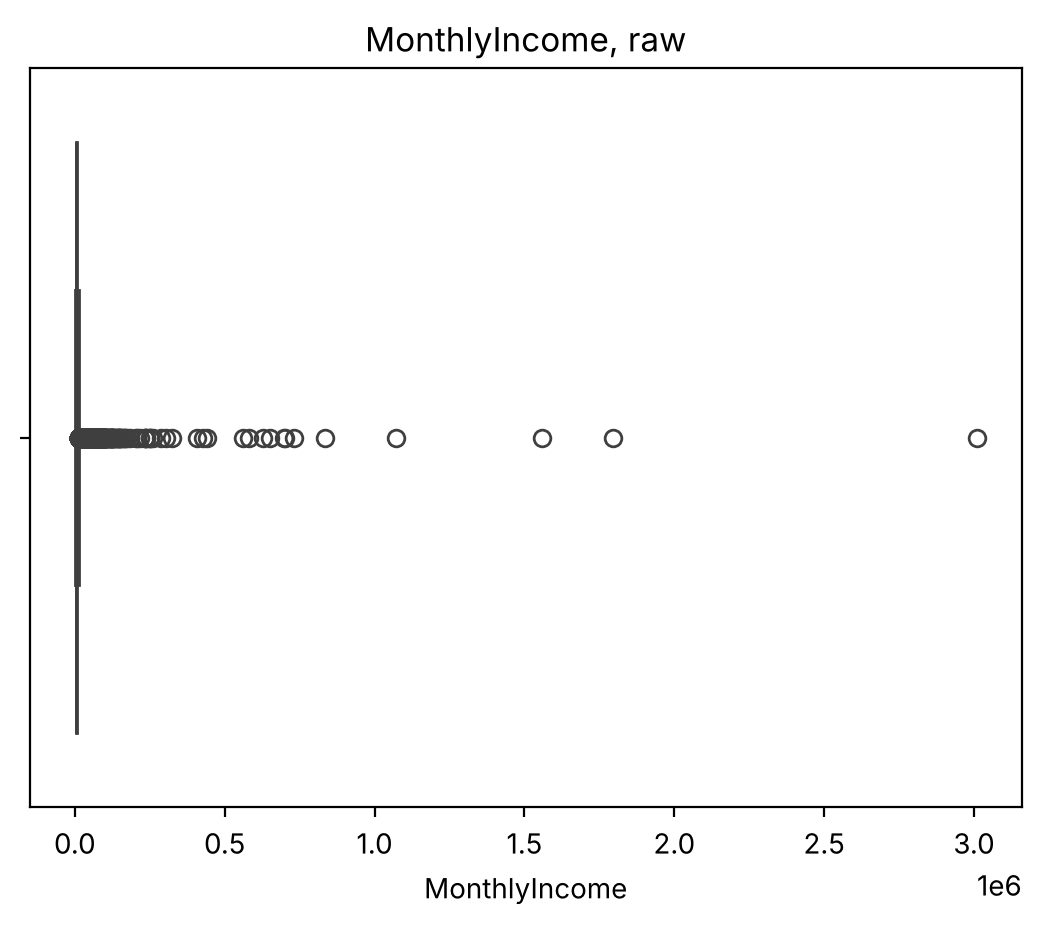

In [57]:
# Raw variable: a few very large incomes squeeze the box against 0 (the axis is in millions)
income = df_fixed["MonthlyIncome"].dropna()

sns.boxplot(x=income)
plt.title("MonthlyIncome, raw")
plt.show()

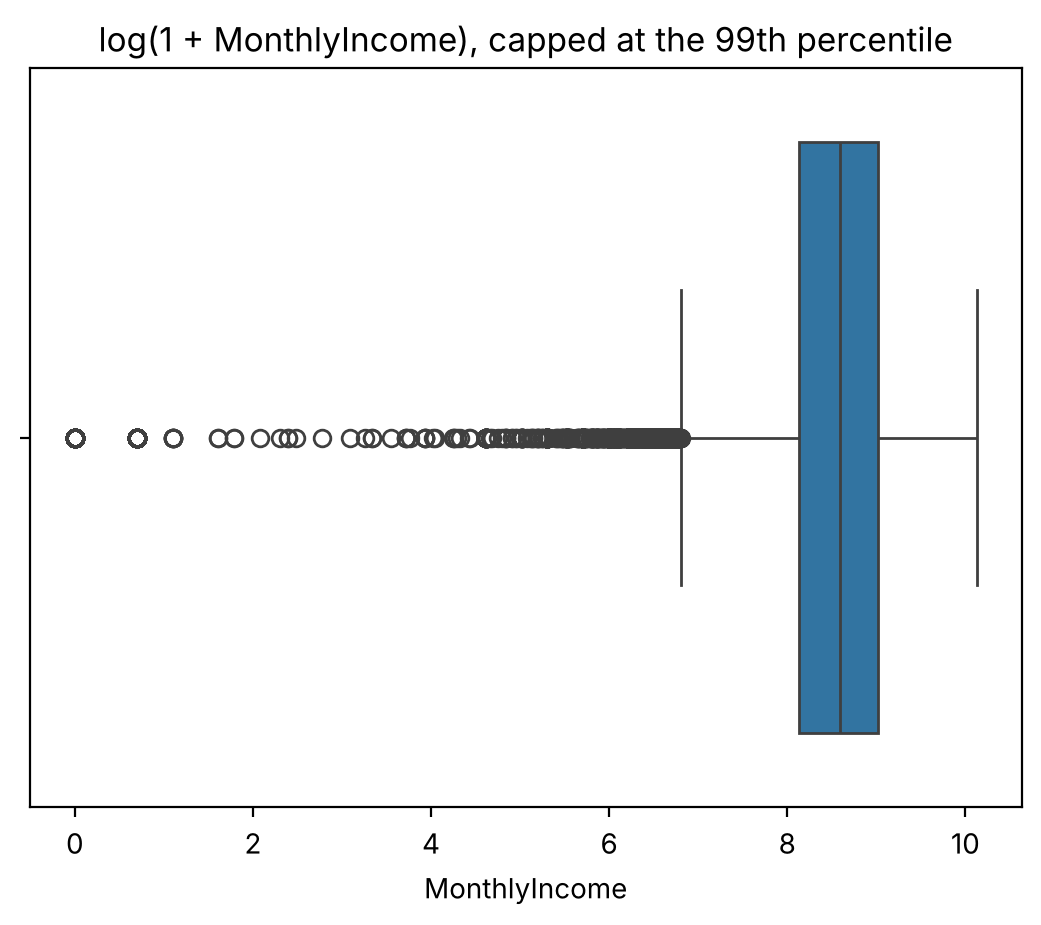

In [58]:
# The treatment decided below: cap at the 99th percentile, then log(1 + x).
# Here the percentile comes from the whole file, only to see the effect.
# In the final submission it will be learned on the training set.
income_treated = np.log1p(income.clip(upper=income.quantile(0.99)))

sns.boxplot(x=income_treated)
plt.title("log(1 + MonthlyIncome), capped at the 99th percentile")
plt.show()

Conclusions:

- The median income is 5,400 and the 99th percentile 25,000, but the maximum is 3,008,750. A few people can earn several hundred thousand a month, so without more information we cannot call these values errors.
- The default rate falls steadily with income, from 9.1% in the lowest quintile to 4.5% in the highest. The highest quintile starts at 9,083, so the extreme incomes are part of a group of 24,020 borrowers and do not show a behaviour of their own.
- In the boxplot of the raw variable the box is squeezed against 0 by a few incomes in the millions, and the body of the data cannot be seen. After the cap and the logarithm the box is centred around 8.6 (an income of about 5,400) and nothing remains far to the right. The points on the left are the incomes below about 900, including the incomes of 0 and 1 that we keep as declared.

Action: cap `MonthlyIncome` at the 99th percentile of the training set and apply log(1 + x), both after the split. We keep the extreme rows. Deleting them would remove real borrowers, and after the cap and the logarithm they no longer weigh more than the rest. The incomes between 1 and 99 from 5.2 are kept as declared, the same decision taken for income 0 in 4.3.

### 5.4 Counts and age

In [59]:
# Counts: 99th percentile, 99.9th percentile and maximum
count_cols = ["NumberOfOpenCreditLinesAndLoans", "NumberRealEstateLoansOrLines", "NumberOfDependents"]

df_fixed[count_cols].describe(percentiles=[0.99, 0.999]).round(1)

,NumberOfOpenCreditLinesAndLoans,NumberRealEstateLoansOrLines,NumberOfDependents
count,150000.0,150000.0,146076.0
mean,8.5,1.0,0.8
std,5.1,1.1,1.1
min,0.0,0.0,0.0
99%,24.0,4.0,4.0
99.9%,34.0,9.0,6.0
max,58.0,54.0,20.0


In [60]:
# Default rate by number of real estate loans (4 or more grouped together)
df_fixed.groupby(df_fixed["NumberRealEstateLoansOrLines"].clip(upper=4))["SeriousDlqin2yrs"].agg(["count", "mean"]).round(3)

,count,mean
NumberRealEstateLoansOrLines,,
0,56188,0.083
1,52338,0.053
2,31522,0.056
3,6300,0.067
4,3652,0.115


In [61]:
# Borrowers over 100 years old and their default rate
df_fixed[df_fixed["age"] > 100][["age", "SeriousDlqin2yrs"]].value_counts()

age    SeriousDlqin2yrs
103.0  0                   3
102.0  0                   3
101.0  0                   2
109.0  0                   2
107.0  0                   1
105.0  0                   1
101.0  1                   1
Name: count, dtype: int64

Conclusions:

- The counts have long right tails: up to 58 open credit lines, 54 real estate loans and 20 dependents, against 99th percentiles of 24, 4 and 4. These values are rare. Only the 54 real estate loans look hard to believe.
- The tail carries information. The default rate is 5.3% with one real estate loan and 11.5% with four or more. Deleting the tail would lose that group.
- The 13 borrowers over 100 years old (maximum 109) include one default. The ages are unusual but possible, and 13 rows cannot affect a model.

Action: keep the counts and the ages as they are. For the linear models of the final submission we will cap the counts at the 99th percentile of the training set. Tree models will use them without changes.

### 5.5 Applying the fixed rules

The rules of 5.1 and 5.2 use fixed thresholds (10 and 100) and no statistic of the data, so we apply them to `df_fixed` now. The caps and the logarithm use percentiles of the data, so they wait until after the split, in the same way as the imputation of section 3:

```python
for col in ["DebtRatio", "MonthlyIncome"]:
    upper = X_train[col].quantile(0.99)            # learned on train only
    X_train[col] = X_train[col].clip(upper=upper)
    X_test[col] = X_test[col].clip(upper=upper)    # same threshold on test

X_train["MonthlyIncome"] = np.log1p(X_train["MonthlyIncome"])
X_test["MonthlyIncome"] = np.log1p(X_test["MonthlyIncome"])
```

In [62]:
# Utilization above 10 is not a ratio: treated as an error
df_fixed.loc[df_fixed["RevolvingUtilizationOfUnsecuredLines"] > 10, "RevolvingUtilizationOfUnsecuredLines"] = np.nan

# A monthly income below 100 cannot pay a debt: DebtRatio holds an amount, as in 4.3
df_fixed.loc[df_fixed["MonthlyIncome"] < 100, "DebtRatio"] = np.nan

df_fixed[["RevolvingUtilizationOfUnsecuredLines", "DebtRatio"]].describe().round(2)

,RevolvingUtilizationOfUnsecuredLines,DebtRatio
count,149759.00,117992.00
mean,0.32,0.39
std,0.37,1.02
min,0.00,0.00
25%,0.03,0.14
50%,0.15,0.29
75%,0.56,0.47
max,8.85,170.40


Utilization now goes from 0 to 8.85 and `DebtRatio` from 0 to 170. The medians do not change (0.15 and 0.29). From here on we use `df_fixed`.

## 6. Relationship with the target

### 6.1 Default rate by variable

We compare the default rate across the values of each variable. For the late-payment counters we group three or more late payments together. For the continuous variables we use quintiles, so each bar holds a fifth of the borrowers.

NumberOfTime30-59DaysPastDueNotWorse
0.0    0.040
1.0    0.150
2.0    0.265
3.0    0.393
Name: SeriousDlqin2yrs, dtype: float64


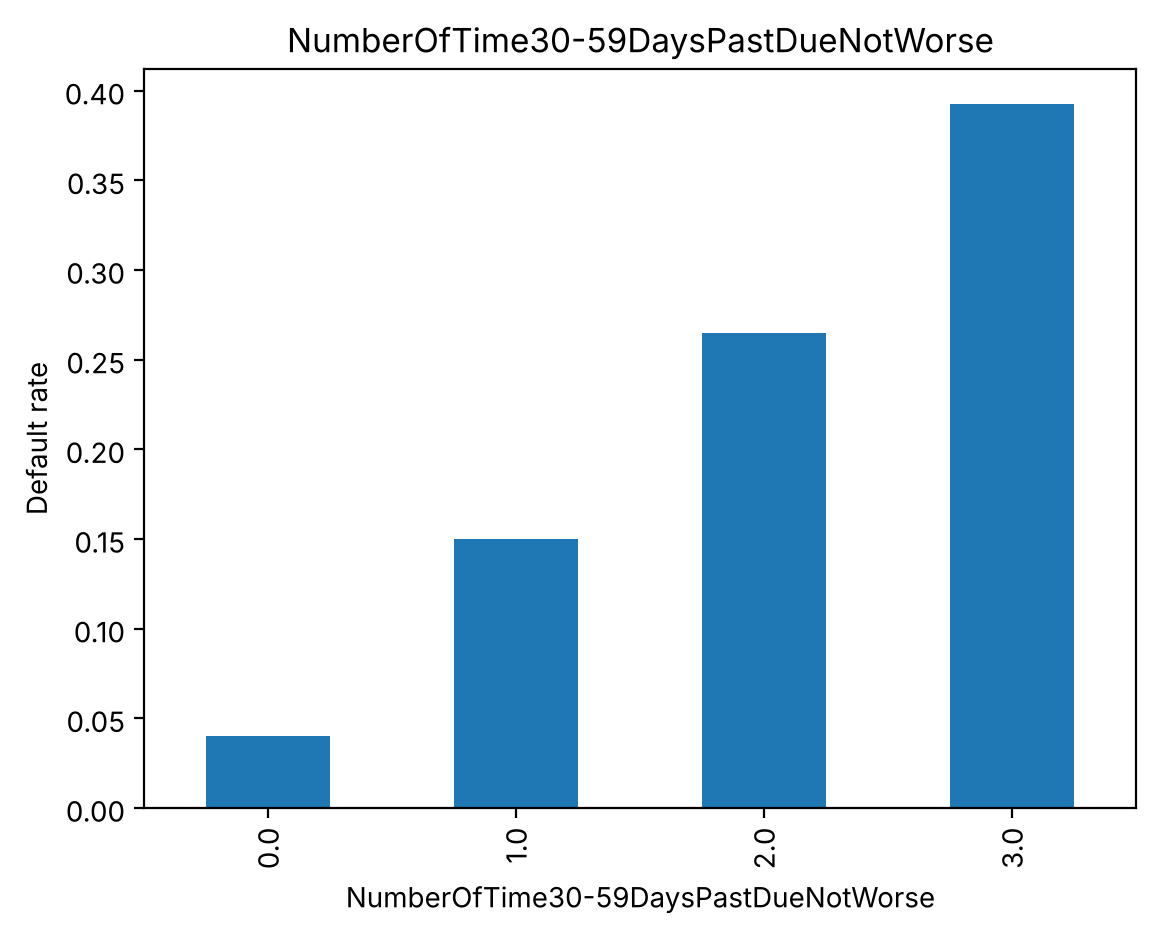

NumberOfTime60-89DaysPastDueNotWorse
0.0    0.051
1.0    0.310
2.0    0.502
3.0    0.586
Name: SeriousDlqin2yrs, dtype: float64


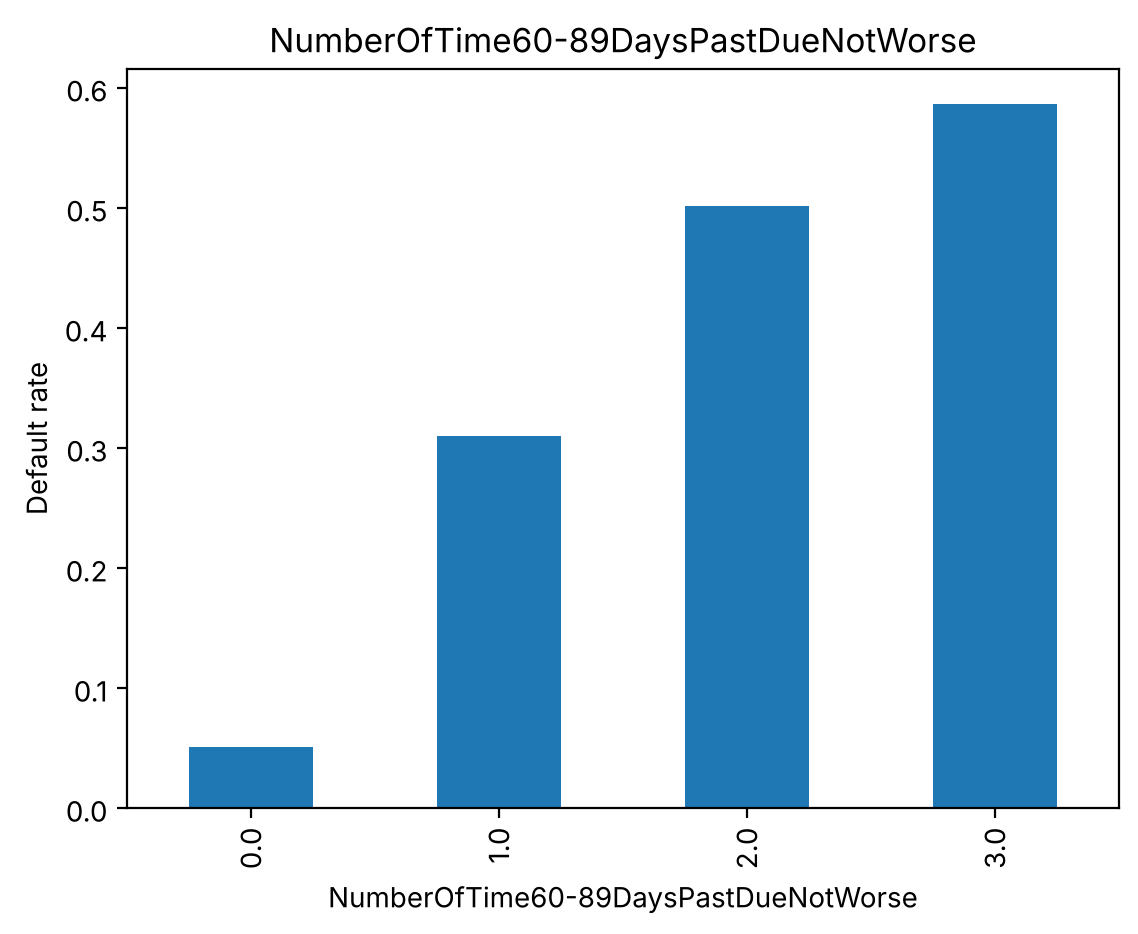

NumberOfTimes90DaysLate
0.0    0.046
1.0    0.337
2.0    0.499
3.0    0.617
Name: SeriousDlqin2yrs, dtype: float64


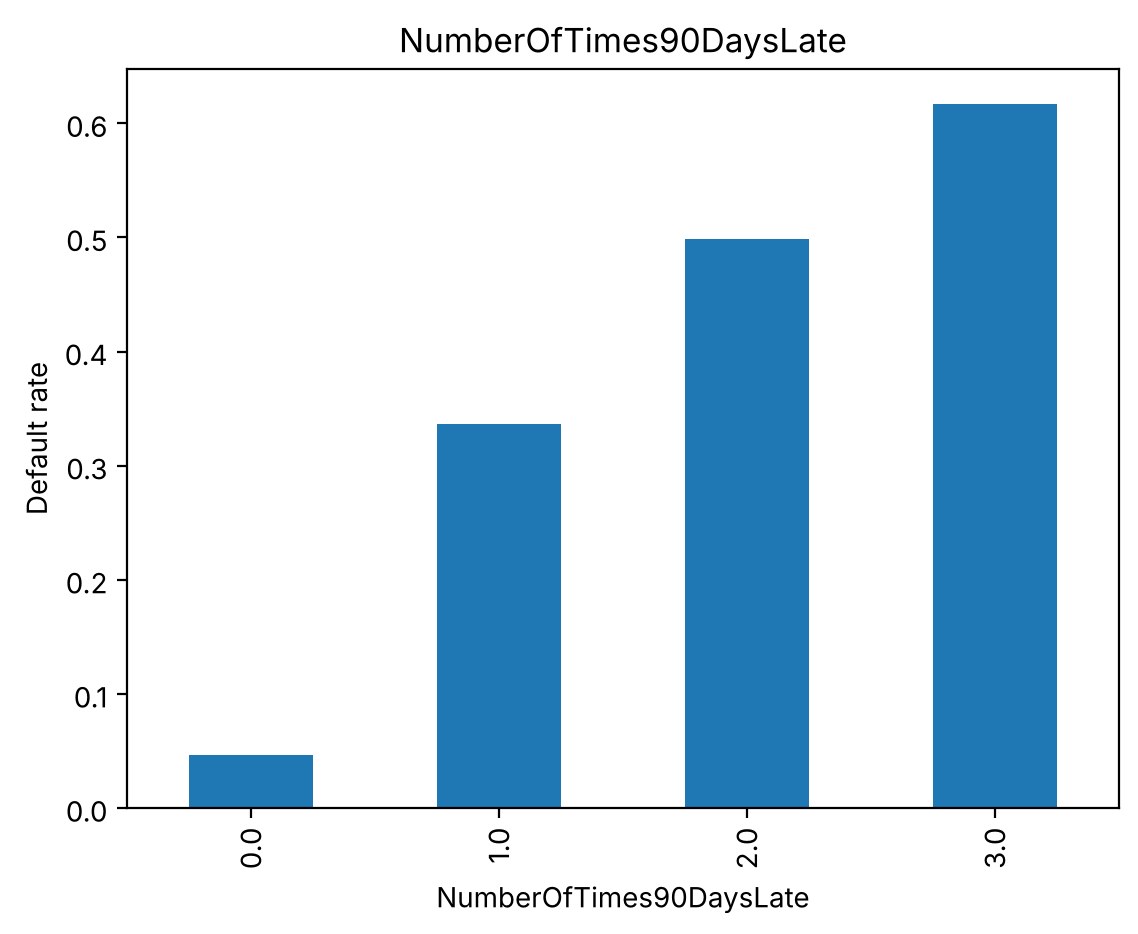

In [63]:
# Default rate by number of late payments (3 or more grouped together)
for col in LATE_COLS:
    rates = df_fixed.groupby(df_fixed[col].clip(upper=3))["SeriousDlqin2yrs"].mean()
    print(rates.round(3))
    rates.plot.bar()
    plt.ylabel("Default rate")
    plt.title(col)
    plt.show()

RevolvingUtilizationOfUnsecuredLines
(-0.001, 0.0192]    0.019
(0.0192, 0.0828]    0.017
(0.0828, 0.27]      0.029
(0.27, 0.695]       0.070
(0.695, 8.852]      0.199
Name: SeriousDlqin2yrs, dtype: float64


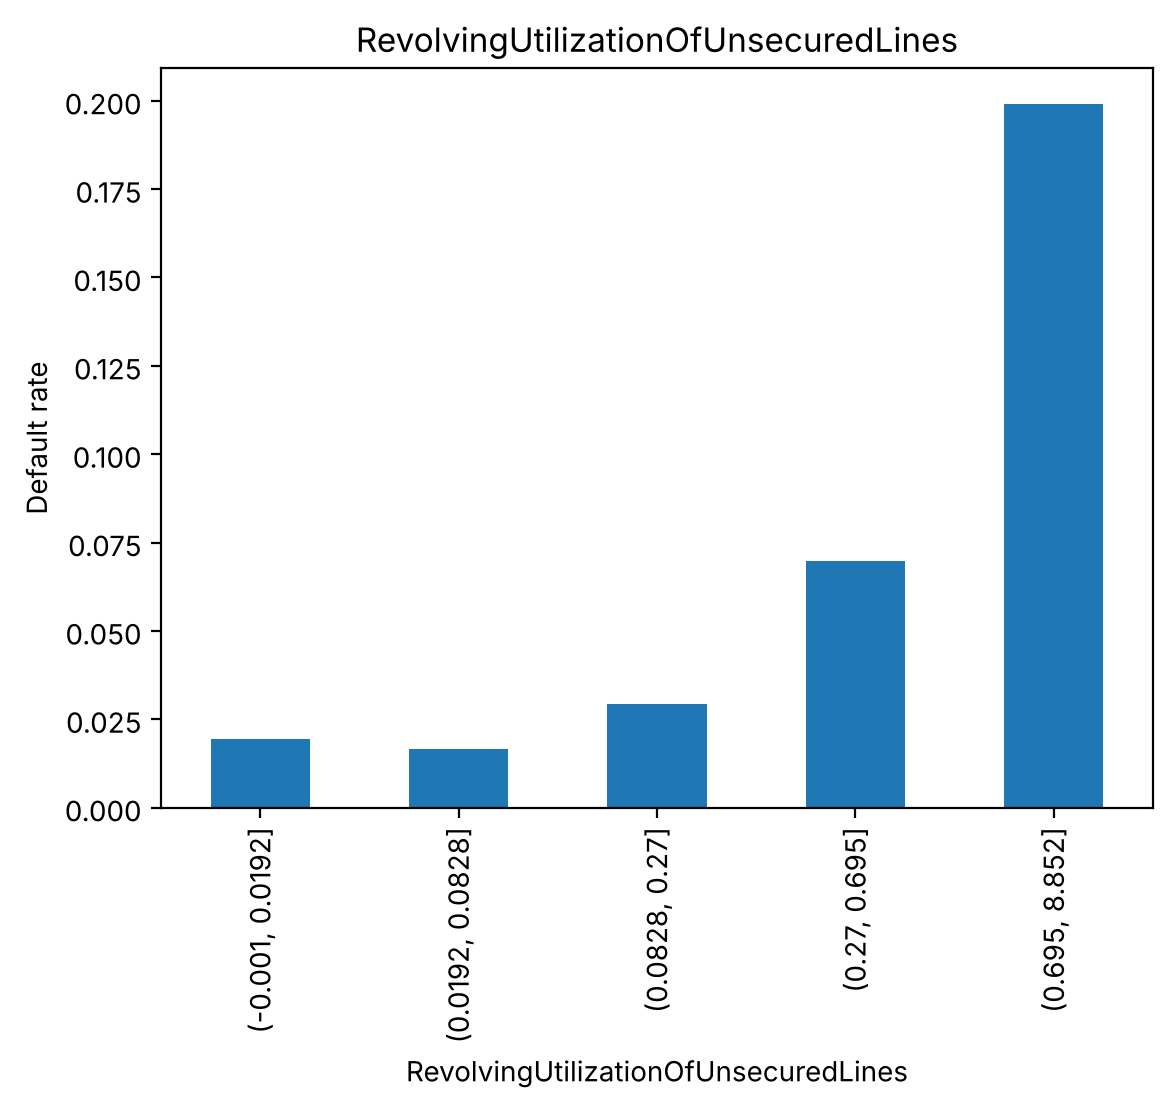

age
(20.999, 39.0]    0.105
(39.0, 48.0]      0.084
(48.0, 56.0]      0.072
(56.0, 65.0]      0.044
(65.0, 109.0]     0.024
Name: SeriousDlqin2yrs, dtype: float64


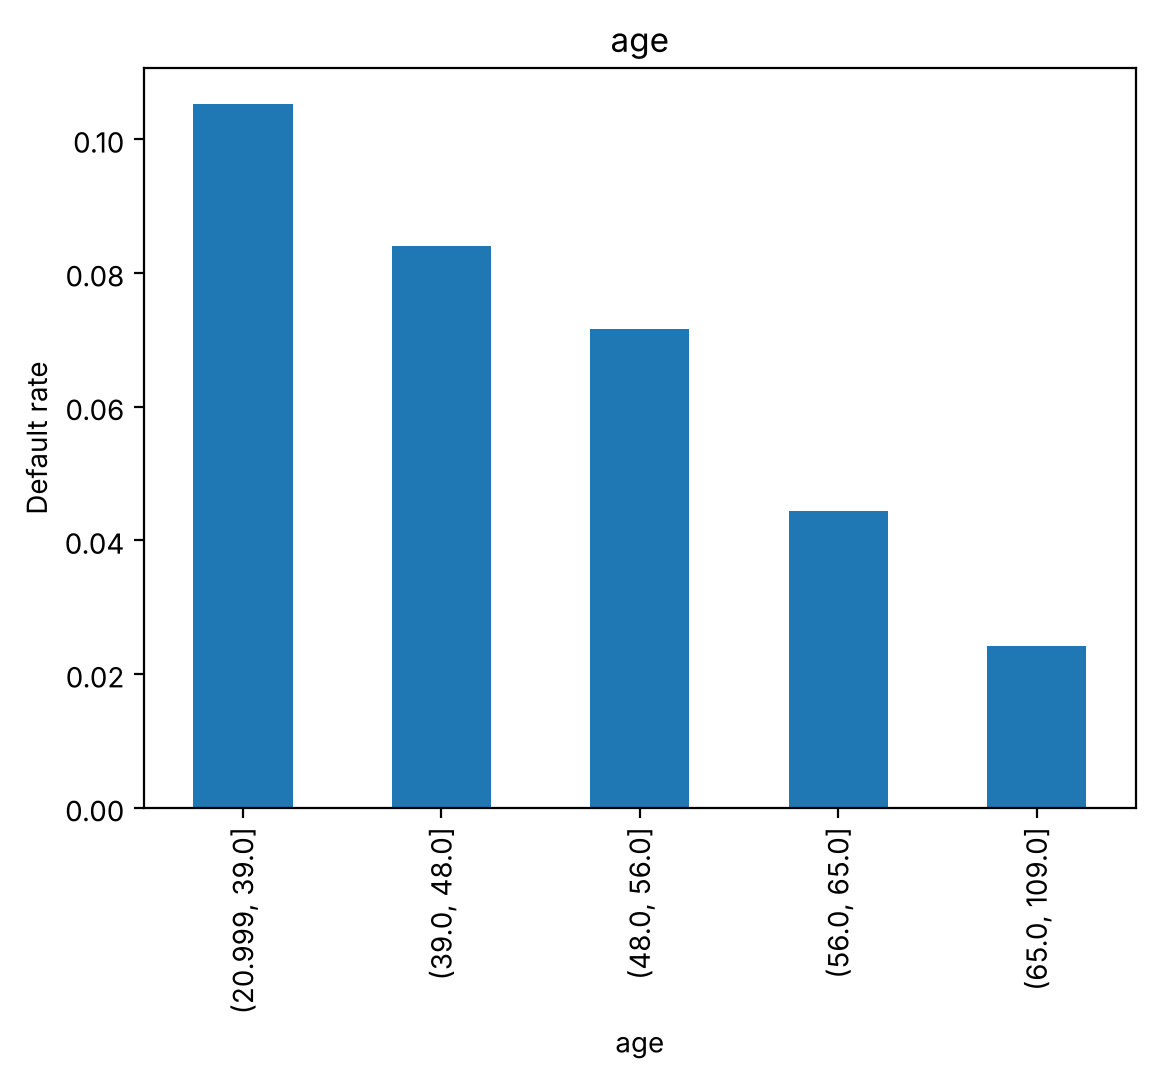

MonthlyIncome
(-0.001, 3000.0]       0.091
(3000.0, 4544.2]       0.086
(4544.2, 6300.0]       0.070
(6300.0, 9083.0]       0.055
(9083.0, 3008750.0]    0.045
Name: SeriousDlqin2yrs, dtype: float64


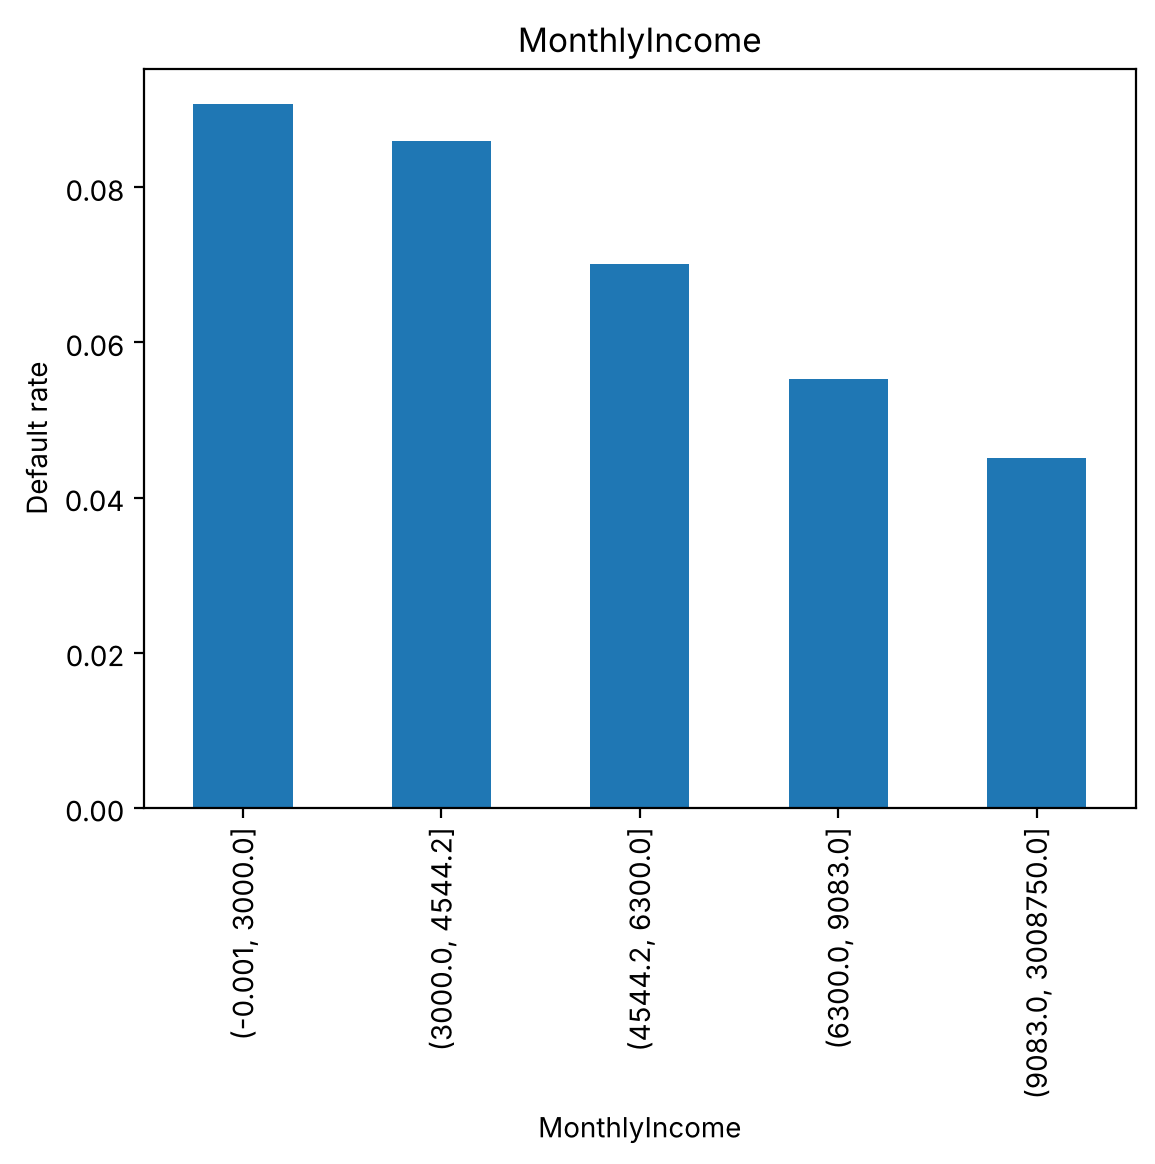

DebtRatio
(-0.001, 0.106]     0.059
(0.106, 0.233]      0.061
(0.233, 0.353]      0.054
(0.353, 0.524]      0.069
(0.524, 170.398]    0.107
Name: SeriousDlqin2yrs, dtype: float64


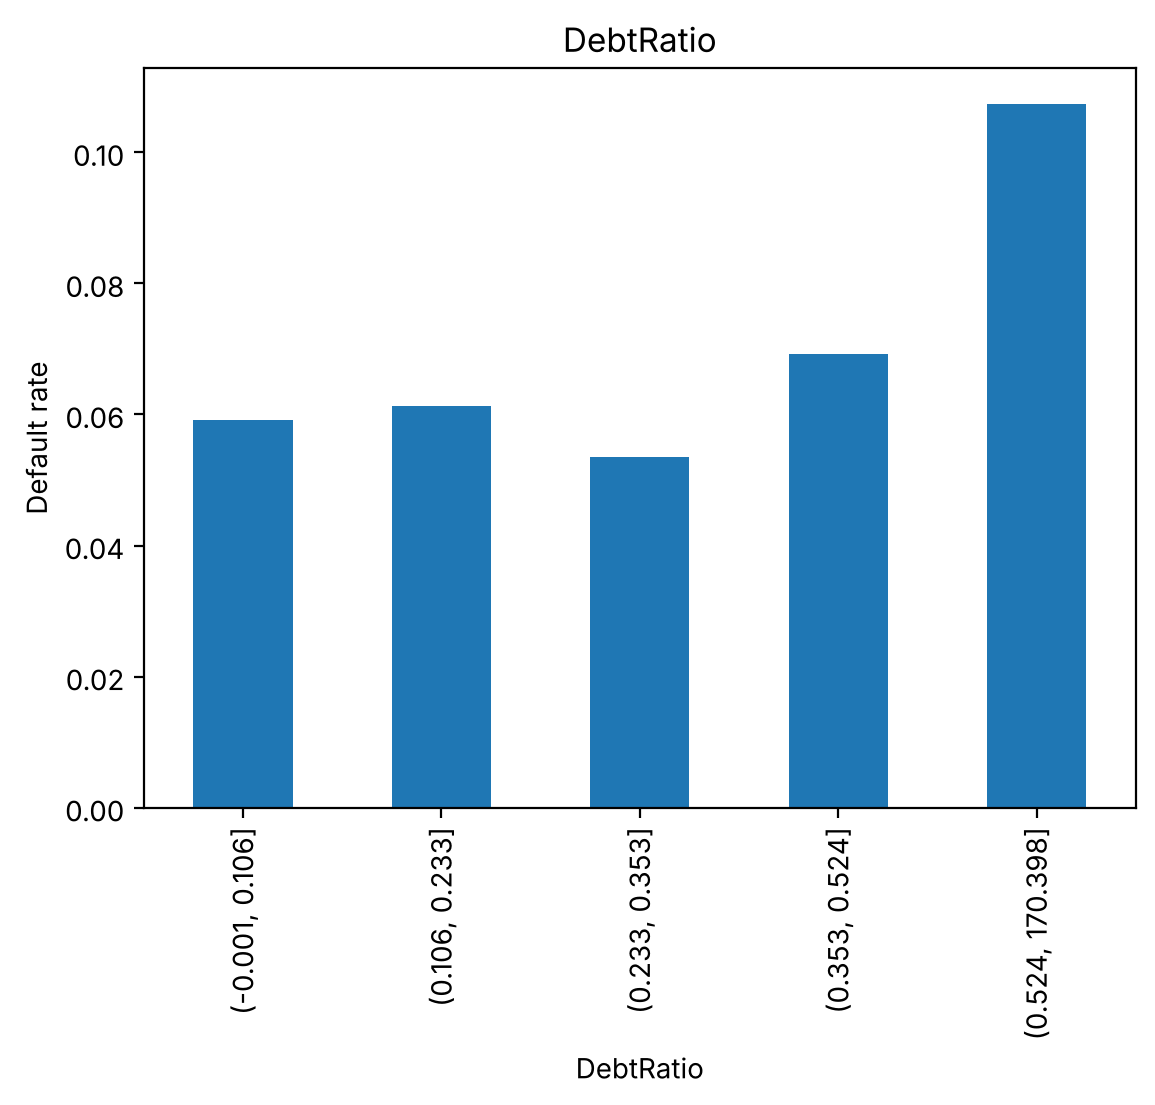

In [64]:
# Default rate by quintile of the continuous variables
for col in ["RevolvingUtilizationOfUnsecuredLines", "age", "MonthlyIncome", "DebtRatio"]:
    quintiles = pd.qcut(df_fixed[col], q=5)
    rates = df_fixed.groupby(quintiles, observed=True)["SeriousDlqin2yrs"].mean()
    print(rates.round(3))
    rates.plot.bar()
    plt.ylabel("Default rate")
    plt.title(col)
    plt.show()

In [65]:
# Default rate by number of open credit lines (quintiles) and of dependents
quintiles = pd.qcut(df_fixed["NumberOfOpenCreditLinesAndLoans"], q=5)
print(df_fixed.groupby(quintiles, observed=True)["SeriousDlqin2yrs"].mean().round(3))

print(df_fixed.groupby(df_fixed["NumberOfDependents"].clip(upper=4))["SeriousDlqin2yrs"].mean().round(3))

NumberOfOpenCreditLinesAndLoans
(-0.001, 4.0]    0.092
(4.0, 6.0]       0.059
(6.0, 9.0]       0.054
(9.0, 12.0]      0.060
(12.0, 58.0]     0.067
Name: SeriousDlqin2yrs, dtype: float64
NumberOfDependents
0.0    0.059
1.0    0.074
2.0    0.081
3.0    0.088
4.0    0.103
Name: SeriousDlqin2yrs, dtype: float64


Conclusions:

- The late-payment counters separate the classes best. One late payment of 90 days or more raises the default rate from 4.6% to 33.7%, and three or more raise it to 61.7%. The other two counters follow the same pattern: from 4.0% to 39.3% (30-59 days) and from 5.1% to 58.6% (60-89 days).
- Utilization is the next strongest variable. The default rate is below 3% in the three lowest quintiles and 19.9% in the highest one (utilization above 0.695).
- Age and income lower the risk. The default rate falls from 10.5% for borrowers under 40 to 2.4% for those over 65, and from 9.1% to 4.5% between the lowest and highest income quintile.
- `DebtRatio` matters only in its highest quintile (10.7%, ratio above 0.52). Below that the rate stays between 5.4% and 6.9%.
- The number of dependents raises the risk slowly, from 5.9% with none to 10.3% with four or more.
- Open credit lines and real estate loans have a U shape. Borrowers with four lines or fewer default more (9.2%) than those with 5 to 12 (5.4% to 6.0%). The same happens with no real estate loan (8.3%) against one (5.3%), and the rate rises again with four or more (11.5%).

Action: all ten variables enter the model. The U shapes are a reason to include tree models among the candidates of the final submission, since a linear model only captures relationships in one direction. For a logistic regression, binning these two variables is an option for the feature engineering.

### 6.2 Correlations

We use the Spearman correlation. It works on the ranks of the values, so extreme values and skewness do not distort it, and it detects any relationship that always goes in the same direction. It does not detect U shapes, so it underestimates the two variables of the last point above.

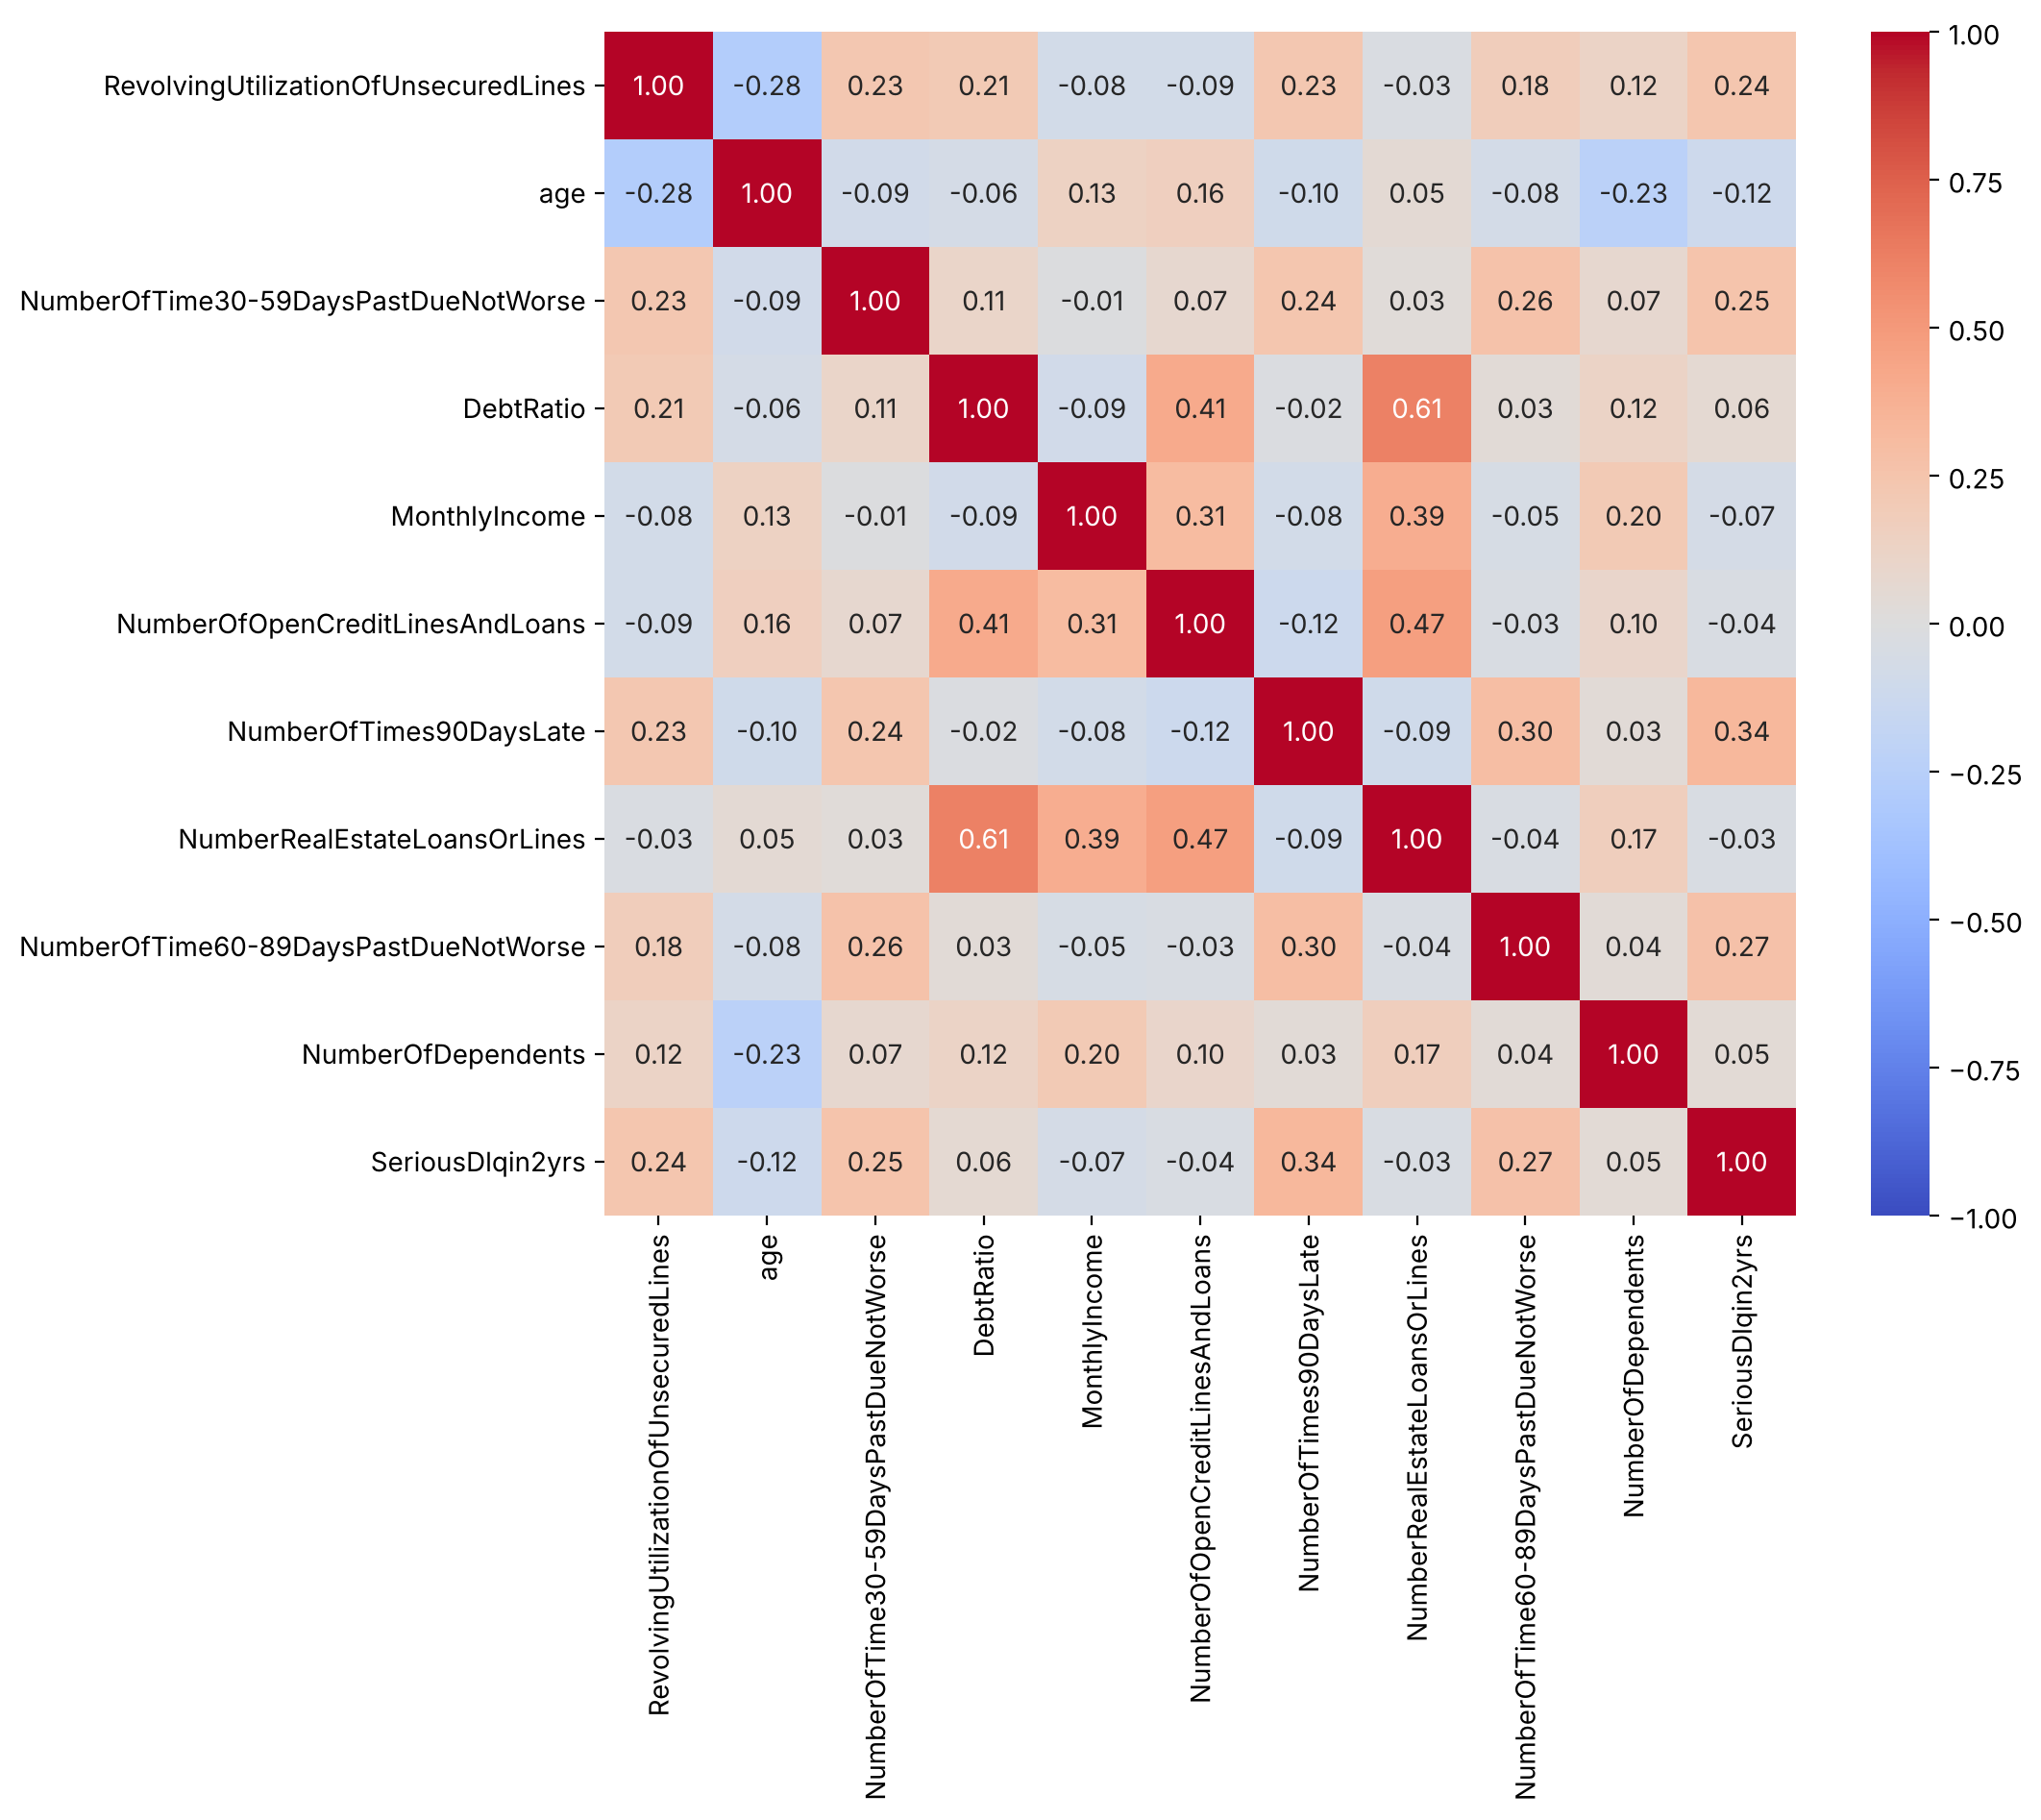

In [66]:
# Spearman correlation: it uses ranks, so extreme values and skewness do not distort it
corr = df_fixed[FEATURES + ["SeriousDlqin2yrs"]].corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

In [67]:
# Pairs of explanatory variables with a correlation above 0.4 (in absolute value)
pairs = corr.drop(index="SeriousDlqin2yrs", columns="SeriousDlqin2yrs").stack()
pairs[(pairs.abs() > 0.4) & (pairs < 1)].round(2)

DebtRatio                        NumberOfOpenCreditLinesAndLoans    0.41
                                 NumberRealEstateLoansOrLines       0.61
NumberOfOpenCreditLinesAndLoans  DebtRatio                          0.41
                                 NumberRealEstateLoansOrLines       0.47
NumberRealEstateLoansOrLines     DebtRatio                          0.61
                                 NumberOfOpenCreditLinesAndLoans    0.47
dtype: float64

In [68]:
# Correlation of each variable with the target, sorted
corr["SeriousDlqin2yrs"].drop("SeriousDlqin2yrs").sort_values()

age                                    -0.117038
MonthlyIncome                          -0.066980
NumberOfOpenCreditLinesAndLoans        -0.038587
NumberRealEstateLoansOrLines           -0.034118
NumberOfDependents                      0.045972
DebtRatio                               0.060224
RevolvingUtilizationOfUnsecuredLines    0.241122
NumberOfTime30-59DaysPastDueNotWorse    0.251440
NumberOfTime60-89DaysPastDueNotWorse    0.268266
NumberOfTimes90DaysLate                 0.335361
Name: SeriousDlqin2yrs, dtype: float64

In [69]:
# The three late-payment counters: Pearson correlation with the 96/98 codes (df)
df[LATE_COLS].corr().round(2)

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate
NumberOfTime30-59DaysPastDueNotWorse,1.00,0.99,0.98
NumberOfTime60-89DaysPastDueNotWorse,0.99,1.00,0.99
NumberOfTimes90DaysLate,0.98,0.99,1.00


In [70]:
# Same correlation once the codes are removed (df_fixed)
df_fixed[LATE_COLS].corr().round(2)

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate
NumberOfTime30-59DaysPastDueNotWorse,1.00,0.31,0.22
NumberOfTime60-89DaysPastDueNotWorse,0.31,1.00,0.29
NumberOfTimes90DaysLate,0.22,0.29,1.00


Conclusions:

- The correlations with the target confirm 6.1: the late-payment counters (0.25 to 0.34) and utilization (0.24) are the strongest. Age is the strongest negative one (-0.12). The rest are below 0.07 in absolute value.
- Between explanatory variables, the highest correlation is 0.61 between `DebtRatio` and `NumberRealEstateLoansOrLines`. A mortgage adds a large monthly payment, so it raises the ratio. The other pairs above 0.4 are open credit lines with real estate loans (0.47) and with `DebtRatio` (0.41). None is high enough to remove a variable.
- With the 96/98 codes, the Pearson correlation between the three late-payment counters is 0.98 to 0.99. Once the codes are removed it falls to 0.22 to 0.31. The 269 rows that carried the same code in the three columns created that correlation. The counters measure different things: a borrower can have late payments of 30 days without ever reaching 90.

Action: keep the three counters as separate variables. The apparent collinearity disappears with the correction of section 4.2. Their sum (total number of late payments) is a candidate aggregation for the feature engineering of the final submission.

## 7. Conclusions

- The data has more errors than its Kaggle description suggests. Missing incomes, incomes of 0 and incomes of 1 turn `DebtRatio` into an amount in more than 32,000 rows. The codes 96 and 98 fake the collinearity of the late-payment counters. Utilization holds values in the thousands. All of them have a fixed rule in this notebook.
- Most errors are informative. The rows with 96/98 codes default 54.7% of the time, and the missing income is related to a lower default rate. We keep that information with the indicators `late_code_flag` and `income_missing` instead of deleting the rows.
- The most useful variables are the late-payment counters, utilization and age. `DebtRatio`, income and the counts add less and in some cases with a U shape.
- After this notebook, `df_fixed` has no impossible values left. The pending steps (imputation, caps and logarithm) depend on the data, so they will be fitted on the training set in the final submission.